In [1]:
# Data Science
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import PLSRegression, PLSCanonical
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import sklearn

import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import scipy

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from PIL import Image
import matplotlib.cm as cm
import matplotlib as mpl
import networkx as nx

# Single-cell RNA sequencing libraries
import anndata
import scanpy as sc
import gseapy as gp
from gseapy import enrichment_map

# General tools
import json
import os
import logging
from roman import toRoman, fromRoman
from pathlib import Path
from tqdm import tqdm
import joblib
from joblib import Parallel, delayed
import time
import re
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
# --- Helper function ---
def overlap(lst1, lst2):
    lst3 = [value for value in lst1 if value in lst2]
    return lst3

In [3]:
# Saved in python.package.version.txt
!conda list

# packages in environment at /host/aristotle/pool8_z0/miniconda3/envs/MERFISH:
#
# Name                    Version                   Build  Channel
_libgcc_mutex             0.1                 conda_forge    conda-forge
_openmp_mutex             4.5                       2_gnu    conda-forge
abc-atlas-access          0.5.0                    pypi_0    pypi
anndata                   0.11.4                   pypi_0    pypi
annotated-types           0.7.0                    pypi_0    pypi
archspec                  0.2.5              pyhd8ed1ab_0    conda-forge
array-api-compat          1.11.2                   pypi_0    pypi
asttokens                 3.0.0              pyhd8ed1ab_1    conda-forge
boltons                   24.0.0             pyhd8ed1ab_1    conda-forge
boto3                     1.37.24                  pypi_0    pypi
botocore                  1.37.24                  pypi_0    pypi
brotli-python             1.1.0           py313h46c70d0_2    conda-forge
bzip2             

In [3]:
# --- Load and inspect data ---
adata_path = '../../../../psy_combined_clean_label.h5ad'
if not os.path.exists(adata_path):
    raise FileNotFoundError(f"{adata_path} not found.")

gene_exp = sc.read_h5ad(adata_path)
print(f"Expression matrix shape: {gene_exp.X.shape}")  # (n_cells, n_genes)

# --- Extract metadata ---
genes = gene_exp.var_names
cells = gene_exp.obs_names

gene_exp_df = pd.DataFrame(gene_exp.X.toarray(),
                           index = gene_exp.obs.index,
                           columns=gene_exp.var.index)

gene_exp_df = gene_exp_df.merge(gene_exp.obs,
                                left_index=True,
                                right_index=True)

genes_list = list(gene_exp.var.index) 
cell_types = np.unique(gene_exp_df.subtype)
print(f"Number of unique cell types: {len(cell_types)}")

# --- Save list of genes for later use ---
np.save('list_of_mouse_genes.npy', genes.to_numpy())
print(f"Saved {len(genes)} gene names to 'list_of_mouse_genes.npy'.")


# --- Identify serotonin-related genes (Htr*) in this dataset ---
bagot_sero = [gene for gene in genes if gene.startswith('Htr')]
print(f"Identified {len(bagot_sero)} serotonin receptor genes (Htr*) in dataset: {bagot_sero}")


# --- Load MERFISH gene list and find overlap ---
merfish_path = 'MERFISH_genes_list.npy'
if not os.path.exists(merfish_path):
    raise FileNotFoundError(f"{merfish_path} not found.")

MERFISH_genes = np.load(merfish_path, allow_pickle=True)
MERFISH_genes = list(map(str, MERFISH_genes))  # ensure string type
print(f"Loaded {len(MERFISH_genes)} MERFISH genes.")

# Overlapping genes between datasets
overlap_genes = overlap(genes, MERFISH_genes)
print(f"Overlap between datasets: {len(overlap_genes)} genes.")


# --- Identify serotonin-related genes (Htr*) in MERFISH ---
MERFISH_sero = [gene for gene in MERFISH_genes if gene.startswith('Htr')]
print(f"Identified {len(MERFISH_sero)} serotonin receptor genes (Htr*) in MERFISH: {MERFISH_sero}")

# Overlap between serotonin genes in both datasets
shared_sero = overlap(MERFISH_sero, bagot_sero)
print(f"Serotonin receptor genes shared between datasets: {shared_sero}")


# --- Load known serotonin genes (from JSON reference) ---
json_path = 'serotonin.json'
if not os.path.exists(json_path):
    raise FileNotFoundError(f"{json_path} not found.")

sero_genes = pd.read_json(json_path)
sero_symbols = sero_genes['approvedSymbol'].str.upper().tolist()
print(f"Loaded {len(sero_symbols)} curated serotonin-related gene symbols.")

# Compare with overlapping genes
genes_upper = [gene.upper() for gene in overlap_genes]
sero_genes_over = overlap(sero_symbols, genes_upper)
print(f"Number of serotonin-related genes overlapping across datasets: {len(sero_genes_over)}")
print(f"Overlapping serotonin genes: {sero_genes_over}")


# --- Known serotonin receptor genes in mouse (for reference) ---
sero_mouse = sorted([
    'Htr5b', 'Htr1d', 'Htr3a', 'Htr1b', 'Htr1a',
    'Htr2a', 'Htr1f', 'Htr4', 'Htr7', 'Htr2c'
])
print(f"Reference serotonin receptor genes in mouse: {sero_mouse}")


Expression matrix shape: (39435, 24600)
Number of unique cell types: 11
Saved 24600 gene names to 'list_of_mouse_genes.npy'.
Identified 17 serotonin receptor genes (Htr*) in dataset: ['Htr2b', 'Htr5b', 'Htr1d', 'Htr6', 'Htr5a', 'Htra3', 'Htra2', 'Htra1', 'Htra4', 'Htr3a', 'Htr1b', 'Htr1a', 'Htr2a', 'Htr1f', 'Htr4', 'Htr7', 'Htr2c']
Loaded 8460 MERFISH genes.
Overlap between datasets: 8264 genes.
Identified 13 serotonin receptor genes (Htr*) in MERFISH: ['Htr2a', 'Htr2c', 'Htr1f', 'Htr1b', 'Htra1', 'Htr1a', 'Htr4', 'Htr7', 'Htr1d', 'Htr3a', 'Htr5b', 'Htr3b', 'Htra3']
Serotonin receptor genes shared between datasets: ['Htr2a', 'Htr2c', 'Htr1f', 'Htr1b', 'Htra1', 'Htr1a', 'Htr4', 'Htr7', 'Htr1d', 'Htr3a', 'Htr5b', 'Htra3']
Loaded 18 curated serotonin-related gene symbols.
Number of serotonin-related genes overlapping across datasets: 9
Overlapping serotonin genes: ['HTR1A', 'HTR1B', 'HTR1D', 'HTR1F', 'HTR2A', 'HTR2C', 'HTR4', 'HTR7', 'HTR3A']
Reference serotonin receptor genes in mouse: [

# Imputed MERFISH spatial transcriptomics

## Loading data

In [4]:
from pathlib import Path
from abc_atlas_access.abc_atlas_cache.abc_project_cache import AbcProjectCache
import anndata
import scanpy as sc

In [5]:
download_base = Path('./abc_atlas')
abc_cache = AbcProjectCache.from_cache_dir(download_base)

print(abc_cache.current_manifest)

cellx =  abc_cache.get_metadata_dataframe(
    directory='MERFISH-C57BL6J-638850-CCF',
    file_name='cell_metadata_with_parcellation_annotation',
    dtype={"cell_label": str,
           "neurotransmitter": str}
)
cellx.set_index('cell_label', inplace=True)
brain_regions_df = cellx[['parcellation_structure']].copy()

/host/aristotle/pool8_z0/miniconda3/envs/MERFISH/lib/python3.13/site-packages/abc_atlas_access/abc_atlas_cache/cloud_cache.py:630: OutdatedManifestWarning: You are loading releases/20250531/manifest.json. A more up to date version of the dataset -- releases/20260228/manifest.json -- exists online. To see the changes between the two versions of the dataset, run
type.compare_manifests('releases/20250531/manifest.json', 'releases/20260228/manifest.json')
To load another version of the dataset, run
type.load_manifest('releases/20260228/manifest.json')
  warnings.warn(msg, OutdatedManifestWarning)


releases/20250531/manifest.json


In [6]:
file = abc_cache.get_data_path(
    directory='MERFISH-C57BL6J-638850-imputed', 
    file_name='C57BL6J-638850-imputed/log2')
print(file)

adata = anndata.read_h5ad(file, backed='r')
gene = adata.var
print(adata.X.shape)

/home/bic/chloes/pool8_z0/Bagot/Psilocybin.Female.Mouse.mPFC/Code/Analysis/PLS/abc_atlas/expression_matrices/MERFISH-C57BL6J-638850-imputed/20240831/C57BL6J-638850-imputed-log2.h5ad
(4334174, 8460)


In [7]:
# rois = ['ACAd', 'ACAv', 'PL', 'ILA', 'ORBl', 'ORBm', 'ORBvl', 'MOs']
rois = ['ACA', 'PL', 'ILA', 'ORB', 'MOs']
rois_idx = dict()

for r in rois :
    
    print(r)
    idx = cellx.loc[cellx.parcellation_structure.str.startswith(r)].index

    print(cellx.loc[cellx.parcellation_structure.str.startswith(r)].parcellation_structure.value_counts())
    print(len(idx))
    rois_idx[r] = idx

ACA
parcellation_structure
ACAv    27707
ACAd    25482
Name: count, dtype: int64
53189
PL
parcellation_structure
PL    18243
Name: count, dtype: int64
18243
ILA
parcellation_structure
ILA    7084
Name: count, dtype: int64
7084
ORB
parcellation_structure
ORBl     21440
ORBvl    15015
ORBm     11627
Name: count, dtype: int64
48082
MOs
parcellation_structure
MOs    90859
Name: count, dtype: int64
90859


In [8]:
download_base = Path('./abc_atlas')
abc_cache = AbcProjectCache.from_cache_dir(download_base)

print(abc_cache.current_manifest)

cellx = abc_cache.get_metadata_dataframe(
    directory='MERFISH-C57BL6J-638850',
    file_name='cell_metadata_with_cluster_annotation',
    dtype={"cell_label": str,
           "neurotransmitter": str}
)
cellx.set_index('cell_label', inplace=True)

file = abc_cache.get_data_path(
    directory='MERFISH-C57BL6J-638850-imputed', 
    file_name='C57BL6J-638850-imputed/log2')
print(file)

# Loading whole-brain atlas with backed='r' argument to avoid loading the full dataset into memory
adata = anndata.read_h5ad(file, backed='r')
gene = adata.var
print(adata.X.shape)

# Store brain sections labels
brain_sections = np.unique(cellx.brain_section_label)

# Filter gene names
gene_filtered = gene.loc[gene.gene_symbol.isin(overlap_genes)].drop_duplicates()
gene_filtered = gene_filtered.reset_index().set_index('gene_symbol').loc[overlap_genes]
print(gene_filtered.head(10))

/host/aristotle/pool8_z0/miniconda3/envs/MERFISH/lib/python3.13/site-packages/abc_atlas_access/abc_atlas_cache/cloud_cache.py:630: OutdatedManifestWarning: You are loading releases/20250531/manifest.json. A more up to date version of the dataset -- releases/20260228/manifest.json -- exists online. To see the changes between the two versions of the dataset, run
type.compare_manifests('releases/20250531/manifest.json', 'releases/20260228/manifest.json')
To load another version of the dataset, run
type.load_manifest('releases/20260228/manifest.json')
  warnings.warn(msg, OutdatedManifestWarning)


releases/20250531/manifest.json
/home/bic/chloes/pool8_z0/Bagot/Psilocybin.Female.Mouse.mPFC/Code/Analysis/PLS/abc_atlas/expression_matrices/MERFISH-C57BL6J-638850-imputed/20240831/C57BL6J-638850-imputed-log2.h5ad
(4334174, 8460)
                gene_identifier
gene_symbol                    
Xkr4         ENSMUSG00000051951
Gm1992       ENSMUSG00000089699
Gm19938      ENSMUSG00000102331
Rp1          ENSMUSG00000025900
Mrpl15       ENSMUSG00000033845
Rgs20        ENSMUSG00000002459
Oprk1        ENSMUSG00000025905
Alkal1       ENSMUSG00000087247
St18         ENSMUSG00000033740
Gm26901      ENSMUSG00000097797


## Receptor expression per ROIs

In [ ]:
# Gather all barcodes from the ROIs
all_idx = np.hstack(list(rois_idx.values()))
print(all_idx.shape)
print(np.unique(all_idx.shape))

gaba_subclasses = ['052 Pvalb Gaba', '053 Sst Gaba', '046 Vip Gaba', '049 Lamp5 Gaba', '047 Sncg Gaba']
cellx['subclass'] = cellx['subclass'].replace(gaba_subclasses, 'GABA')

reversed_cell_mapping = {
    '032 L5 NP CTX Glut': 'L5/6 NP',
    '030 L6 CT CTX Glut': 'L6 CT',
    '006 L4/5 IT CTX Glut': 'L2-6 IT',
    '022 L5 ET CTX Glut': 'L5 PT',
    'GABA': 'GABA',
}

print(reversed_cell_mapping.values())

# Keeping only neurons of the ROIs (all_idx)
neuronx = cellx.loc[all_idx].loc[cellx['subclass'].isin(list(reversed_cell_mapping.keys()))].copy()
print(neuronx.shape)
neuronx = neuronx.merge(brain_regions_df, left_index=True, right_index=True)
neuronx['parcellation_structure'] = neuronx['parcellation_structure'].replace({'ACAd': 'ACA',
                                                                                'ACAv': 'ACA',
                                                                                'ORBl' : 'ORB',
                                                                                'ORBm' : 'ORB',
                                                                                'ORBvl' : 'ORB'})
print(neuronx.shape)
print(neuronx.index[0:5])

filename = f'ROIs_neurons.h5ad'
adata_subset = adata[neuronx.index].to_df()
gdata = anndata.AnnData(adata_subset)
gdata.obs = neuronx.copy()
gdata.var = adata[neuronx.index].var.copy().set_index('gene_symbol')

gdata.var_names_make_unique()
sc.settings.set_figure_params(dpi=200, dpi_save=200, fontsize=11)
sc.pl.dotplot(gdata,
            ['Htr2a'],
            groupby='parcellation_structure',
            var_group_rotation = 45.0,
            colorbar_title = 'Average expression',
            size_title = '% detected',
            swap_axes = False,
            vmax = 10, 
            vmin = 0,
            # title=r,
            figsize=(2,3),
            dendrogram=False,
            save=f'Htr2a.png',
            )

del gdata
del adata_subset


(217457,)
[217457]
dict_values(['L5/6 NP', 'L6 CT', 'L2-6 IT', 'L5 PT', 'GABA'])
(90595, 20)
(90595, 21)
Index(['1017155956100990406-1', '1017155956101370476-2', '1018133836201540362',
       '1017155956102480197-1', '1018093345102330114-1'],
      dtype='object', name='cell_label')


(217457,)
[217457]
dict_values(['L5/6 NP', 'L6 CT', 'L2-6 IT', 'L5 PT', 'GABA'])
(90595, 20)
(90595, 21)
Index(['1017155956100990406-1', '1017155956101370476-2', '1018133836201540362',
       '1017155956102480197-1', '1018093345102330114-1'],
      dtype='object', name='cell_label')


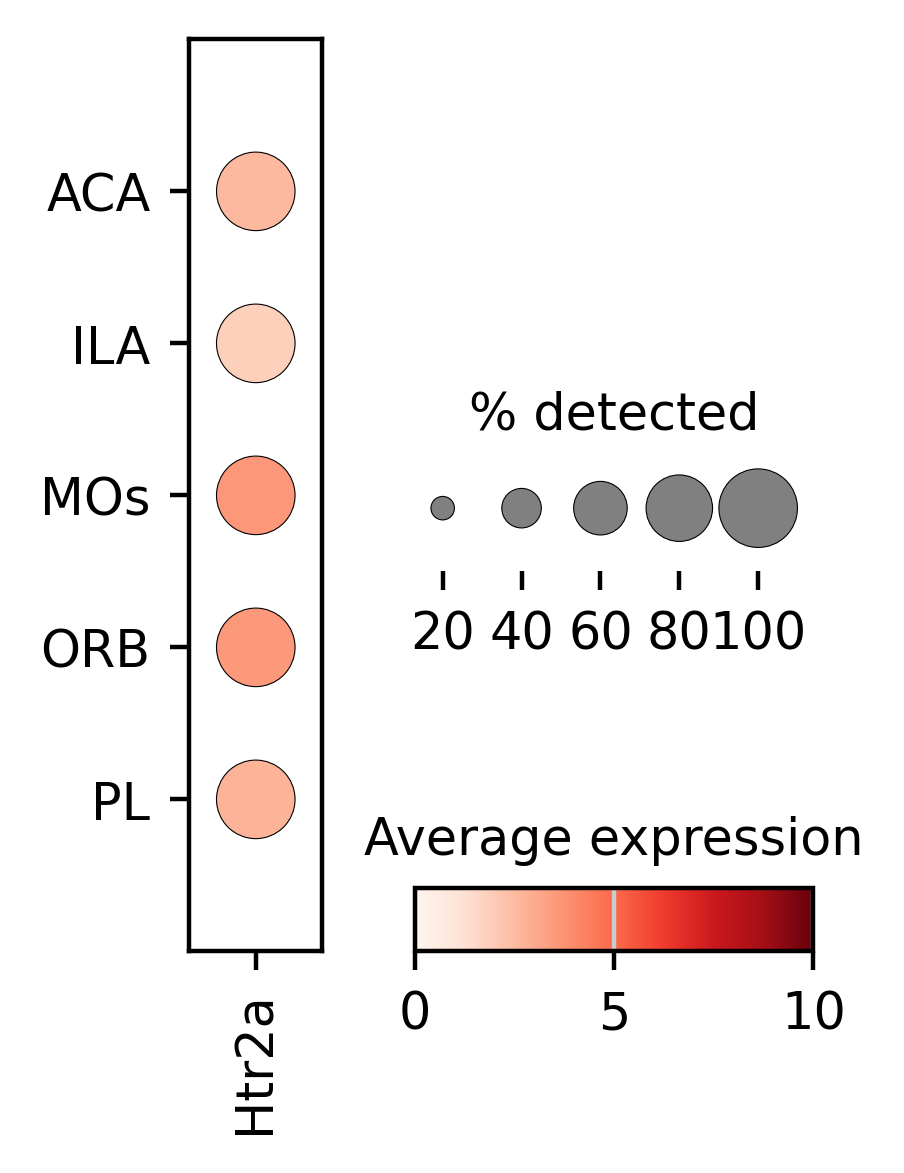

In [ ]:
# Gather all barcodes from the ROIs
all_idx = np.hstack(list(rois_idx.values()))
print(all_idx.shape)
print(np.unique(all_idx.shape))

gaba_subclasses = ['052 Pvalb Gaba', '053 Sst Gaba', '046 Vip Gaba', '049 Lamp5 Gaba', '047 Sncg Gaba']
cellx['subclass'] = cellx['subclass'].replace(gaba_subclasses, 'GABA')

reversed_cell_mapping = {
    '032 L5 NP CTX Glut': 'L5/6 NP',
    '030 L6 CT CTX Glut': 'L6 CT',
    '006 L4/5 IT CTX Glut': 'L2-6 IT',
    '022 L5 ET CTX Glut': 'L5 PT',
    'GABA': 'GABA',
}

print(reversed_cell_mapping.values())

# Keeping only neurons of the ROIs (all_idx)
neuronx = cellx.loc[all_idx].loc[cellx['subclass'].isin(list(reversed_cell_mapping.keys()))].copy()
print(neuronx.shape)
neuronx = neuronx.merge(brain_regions_df, left_index=True, right_index=True)
neuronx['parcellation_structure'] = neuronx['parcellation_structure'].replace({'ACAd': 'ACA',
                                                                                'ACAv': 'ACA',
                                                                                'ORBl' : 'ORB',
                                                                                'ORBm' : 'ORB',
                                                                                'ORBvl' : 'ORB'})
print(neuronx.shape)
print(neuronx.index[0:5])

filename = f'ROIs_neurons.h5ad'
adata_subset = adata[neuronx.index].to_df()
gdata = anndata.AnnData(adata_subset)
gdata.obs = neuronx.copy()
gdata.var = adata[neuronx.index].var.copy().set_index('gene_symbol')

gdata.var_names_make_unique()
sc.settings.set_figure_params(dpi=200, dpi_save=200, fontsize=11)
sc.pl.dotplot(gdata,
            ['Htr2a'],
            groupby='parcellation_structure',
            var_group_rotation = 45.0,
            colorbar_title = 'Average expression',
            size_title = '% detected',
            swap_axes = False,
            vmax = 10, 
            vmin = 0,
            # title=r,
            figsize=(2,3),
            dendrogram=False,
            save=f'Htr2a.svg',
            )

del gdata
del adata_subset


ACA
53189
(53189, 20)
Index(['1017155956100990406-1', '1017155956101370476-2', '1018133836201540362',
       '1017155956102480197-1', '1018093345102330114-1'],
      dtype='object', name='cell_label')


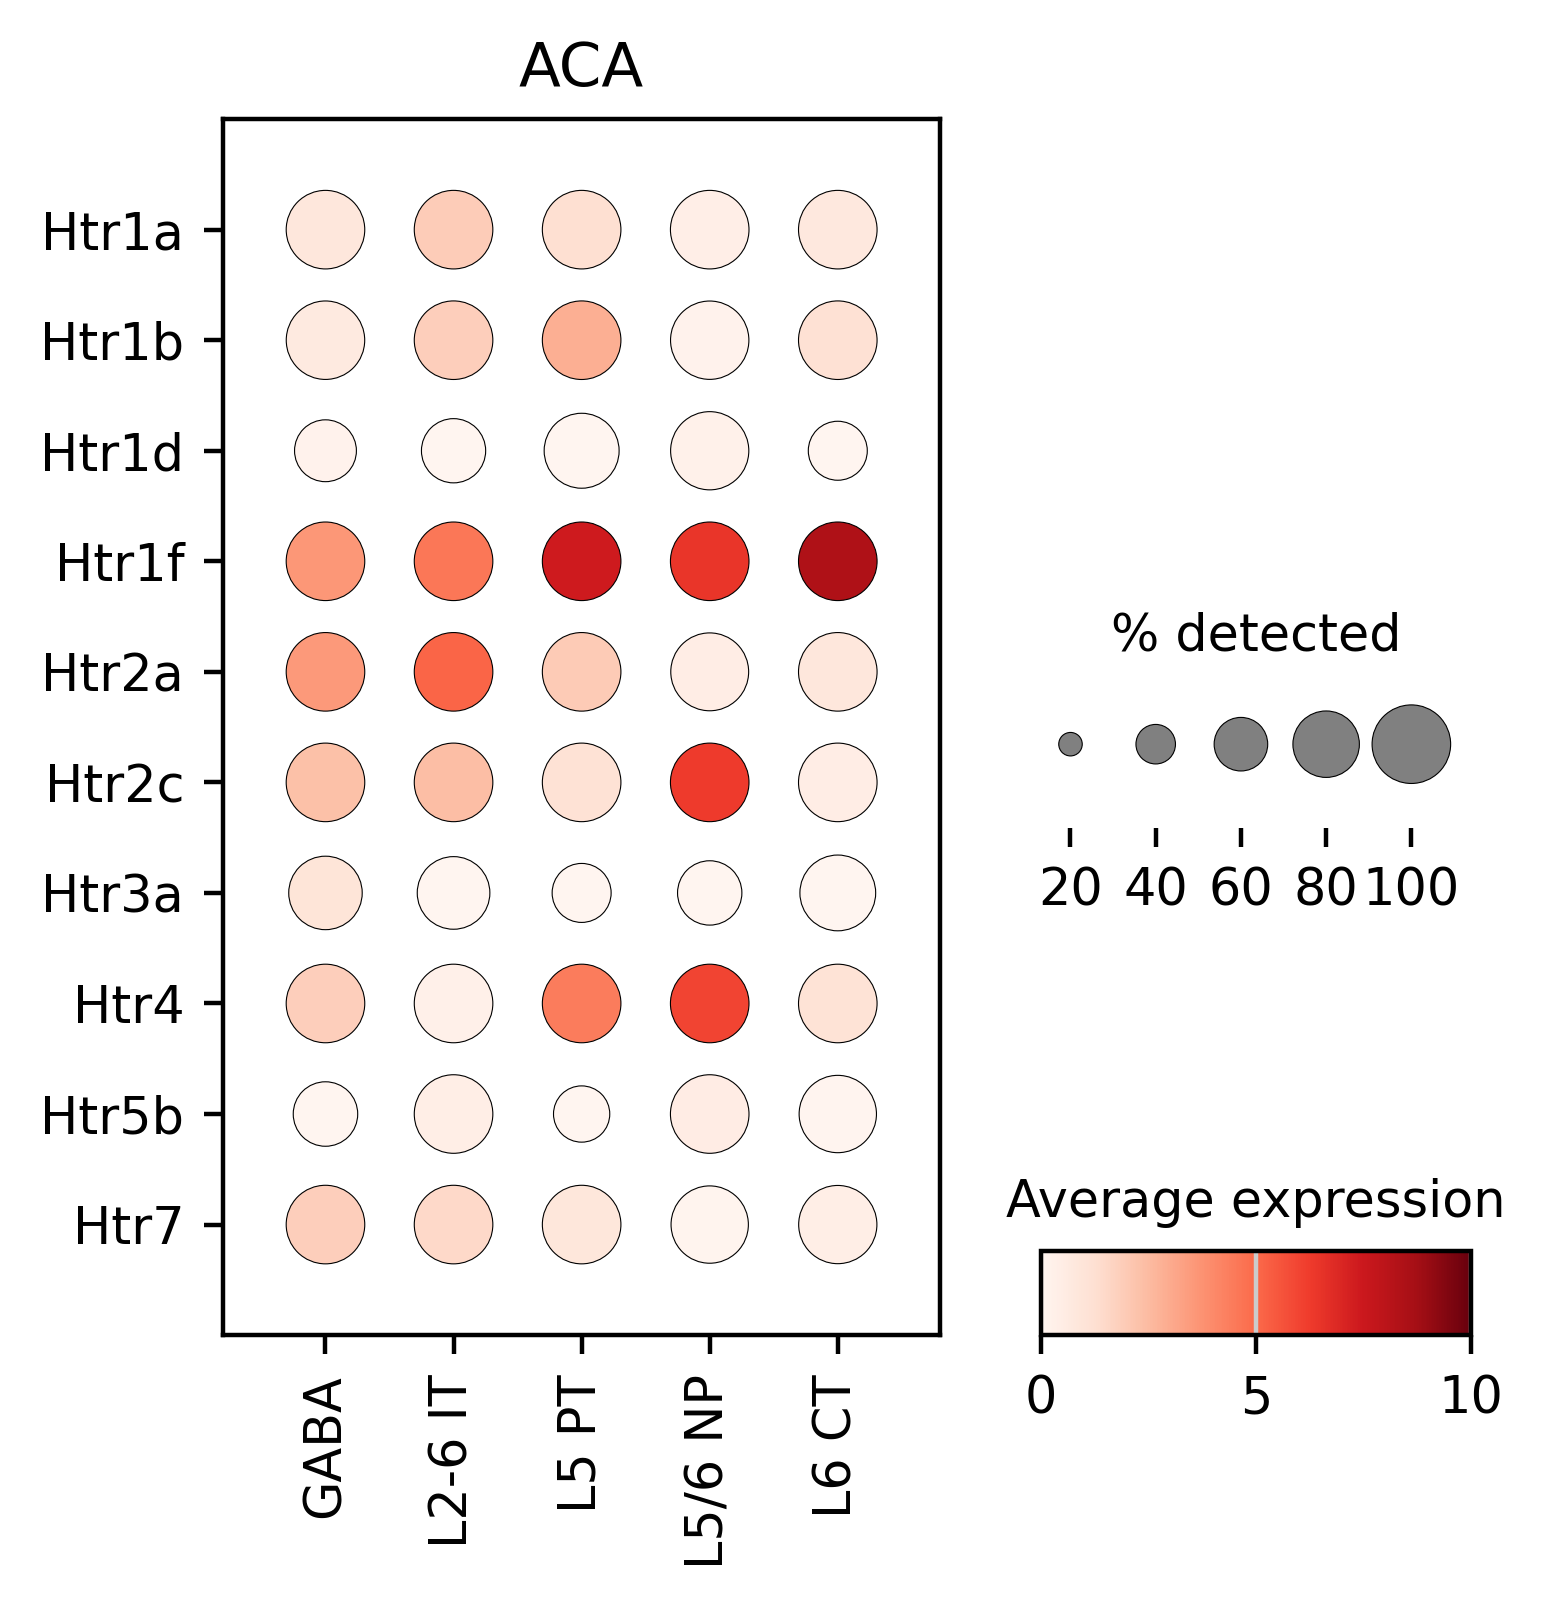

PL
18243
(18243, 20)
Index(['1017184920101060352', '1018143557100550438', '1017163940201200212',
       '1017163940101180609', '1017184920100930042'],
      dtype='object', name='cell_label')


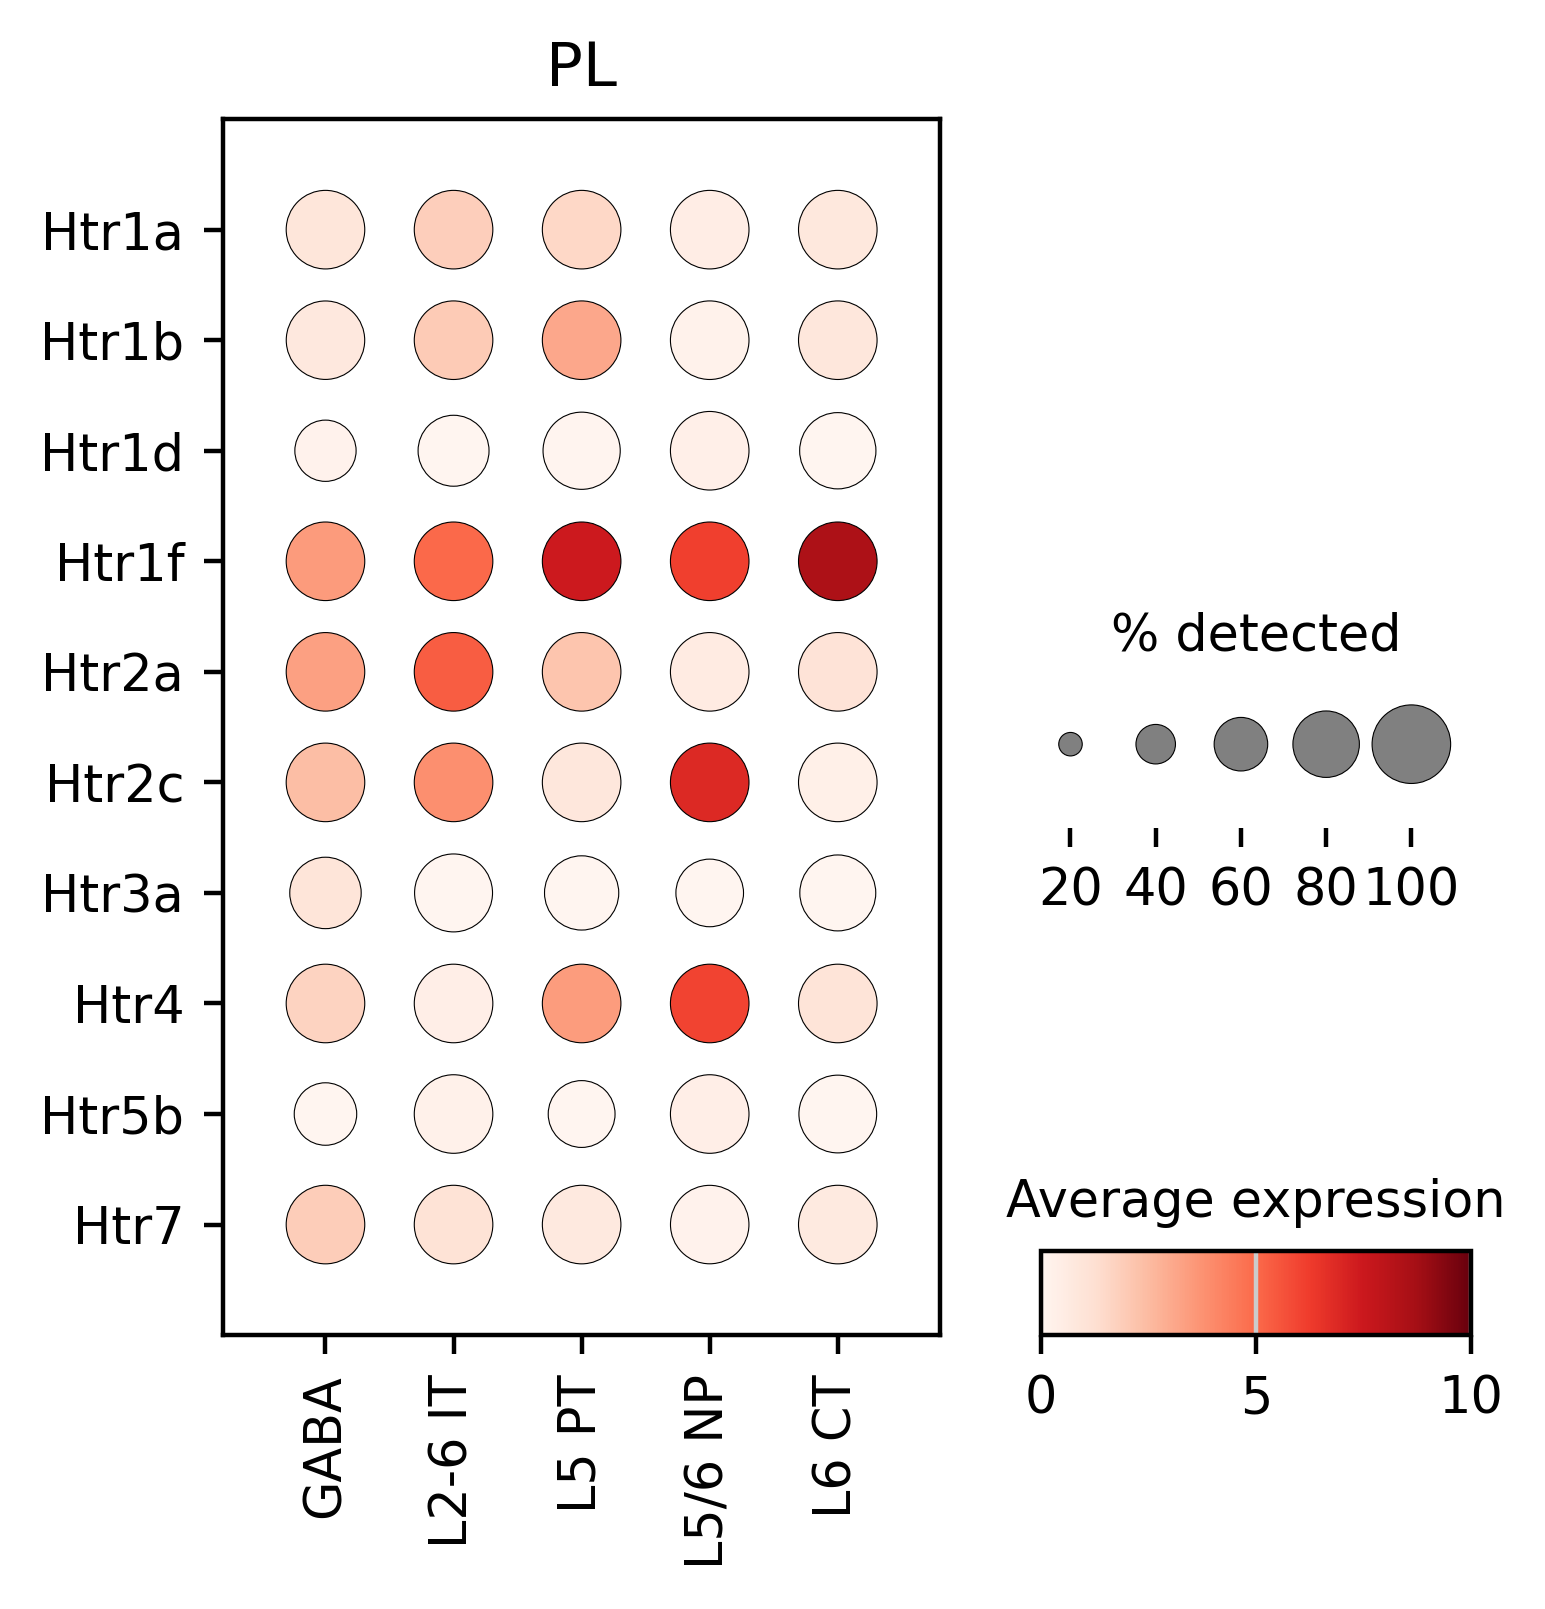

ILA
7084
(7084, 20)
Index(['1018143423101190294', '1018143423101500380', '1018143423101520733',
       '1017163940100910311', '1017165415101330425'],
      dtype='object', name='cell_label')


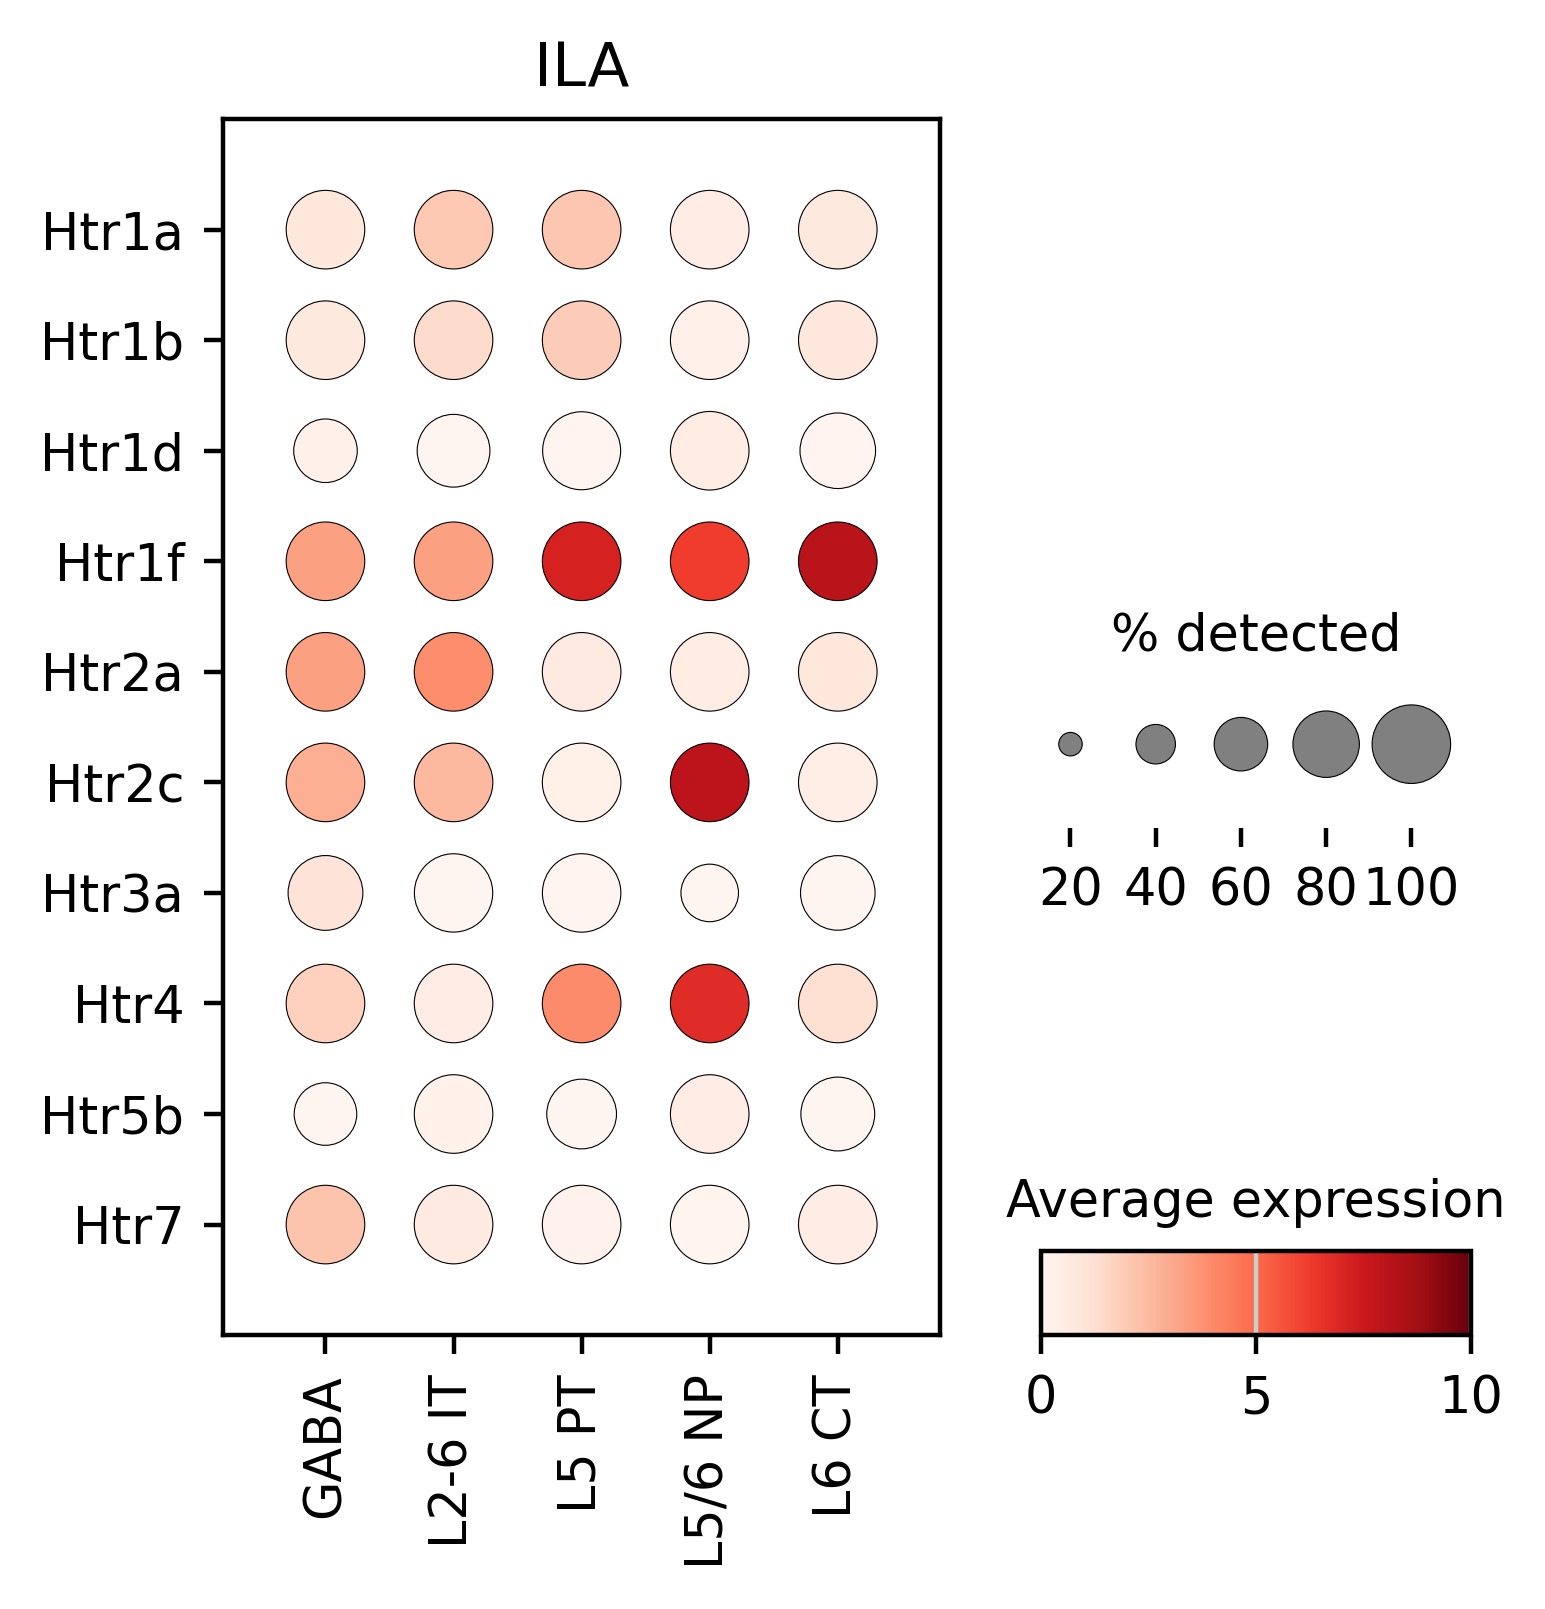

ORB
48082
(48082, 20)
Index(['1017184920100950069', '1017184920100570188', '1018143423101010419',
       '1018143557100830276', '1017163940100630248'],
      dtype='object', name='cell_label')


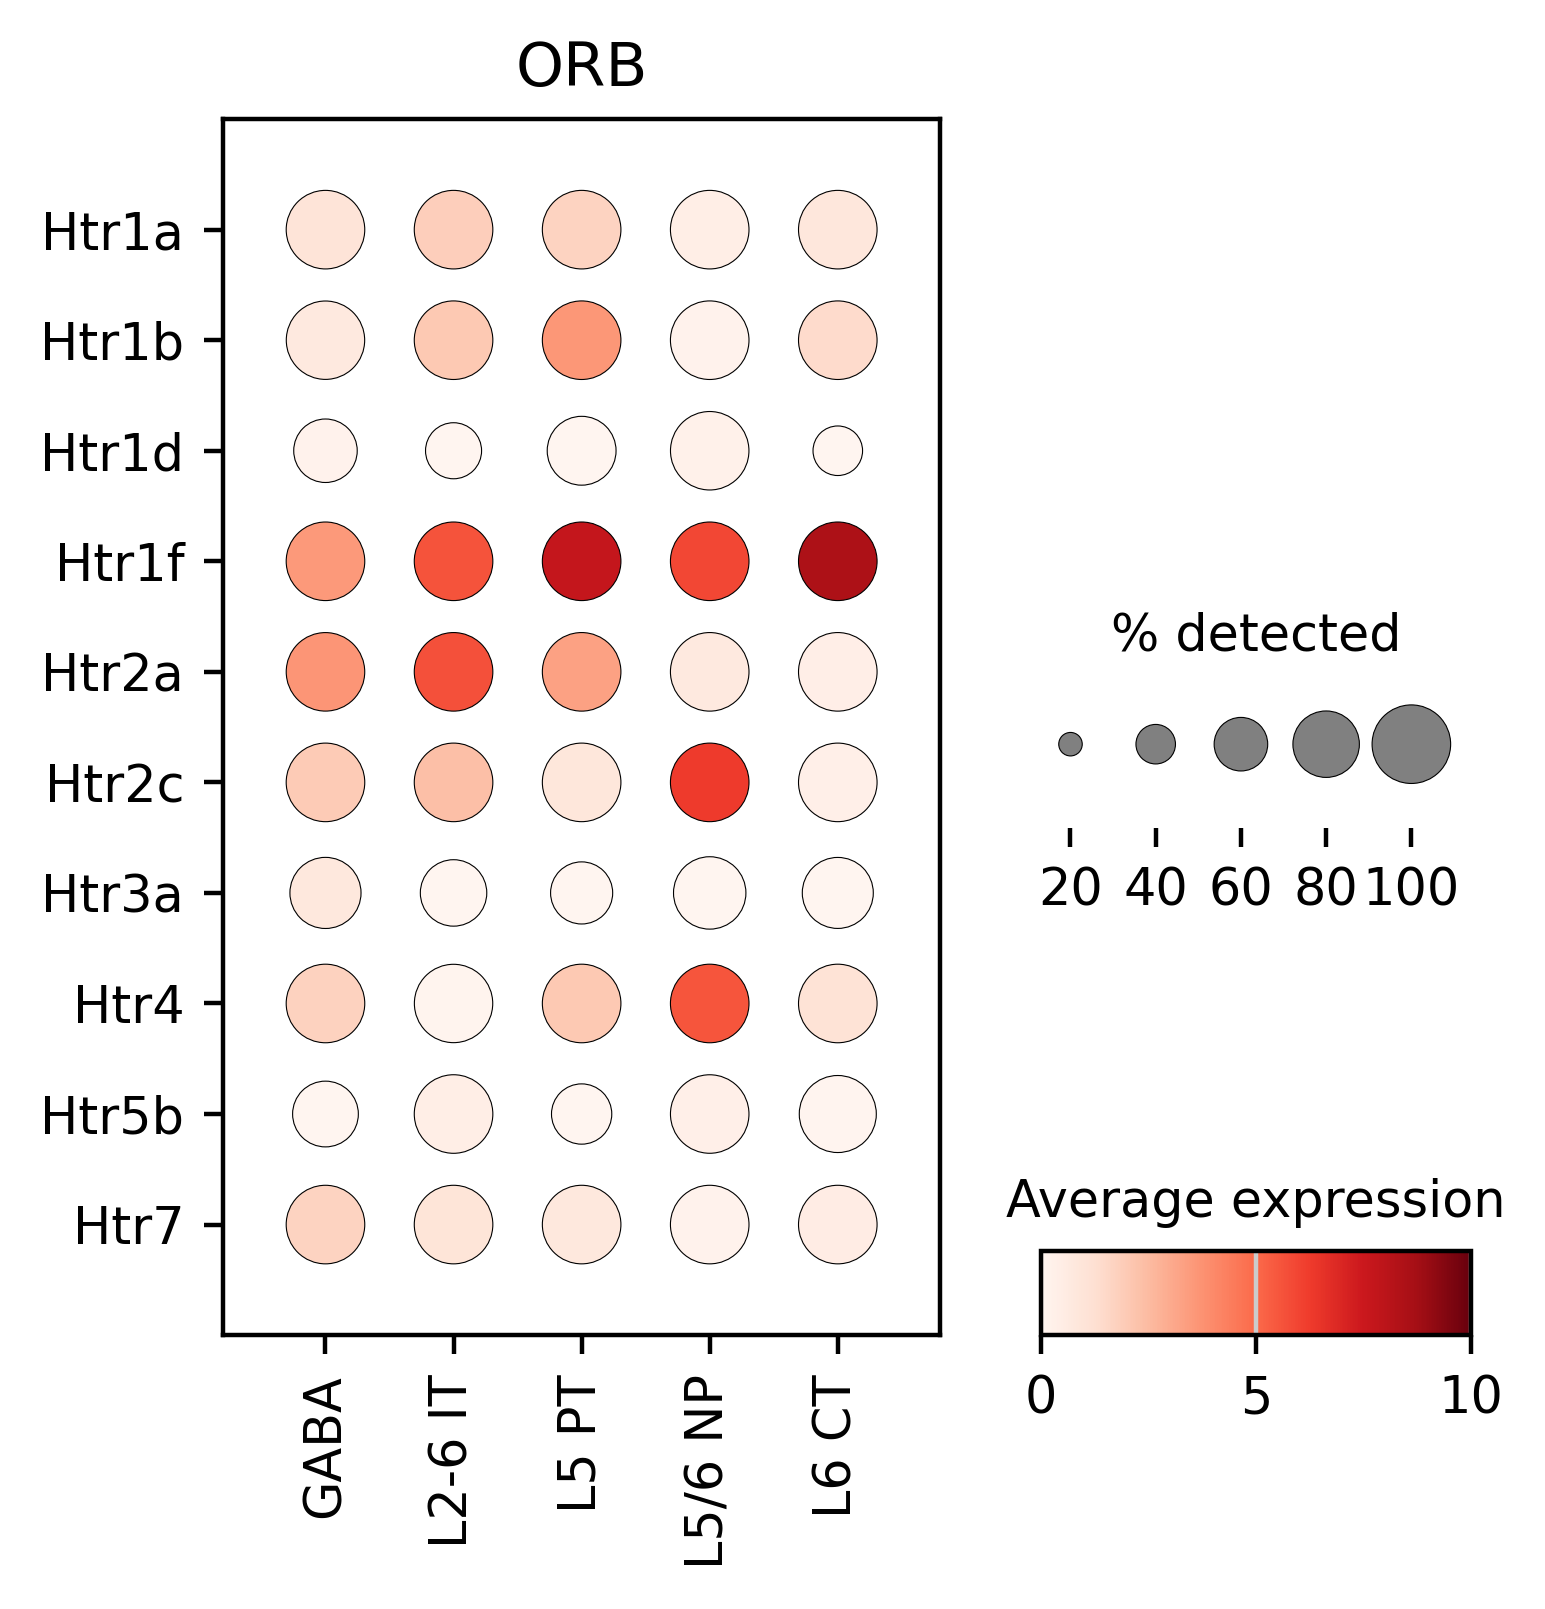

MOs
90859
(90859, 20)
Index(['1018143423100710083', '1017165415201490507', '1017155956101710432',
       '1104095349100610225', '1104095349100690354-4'],
      dtype='object', name='cell_label')


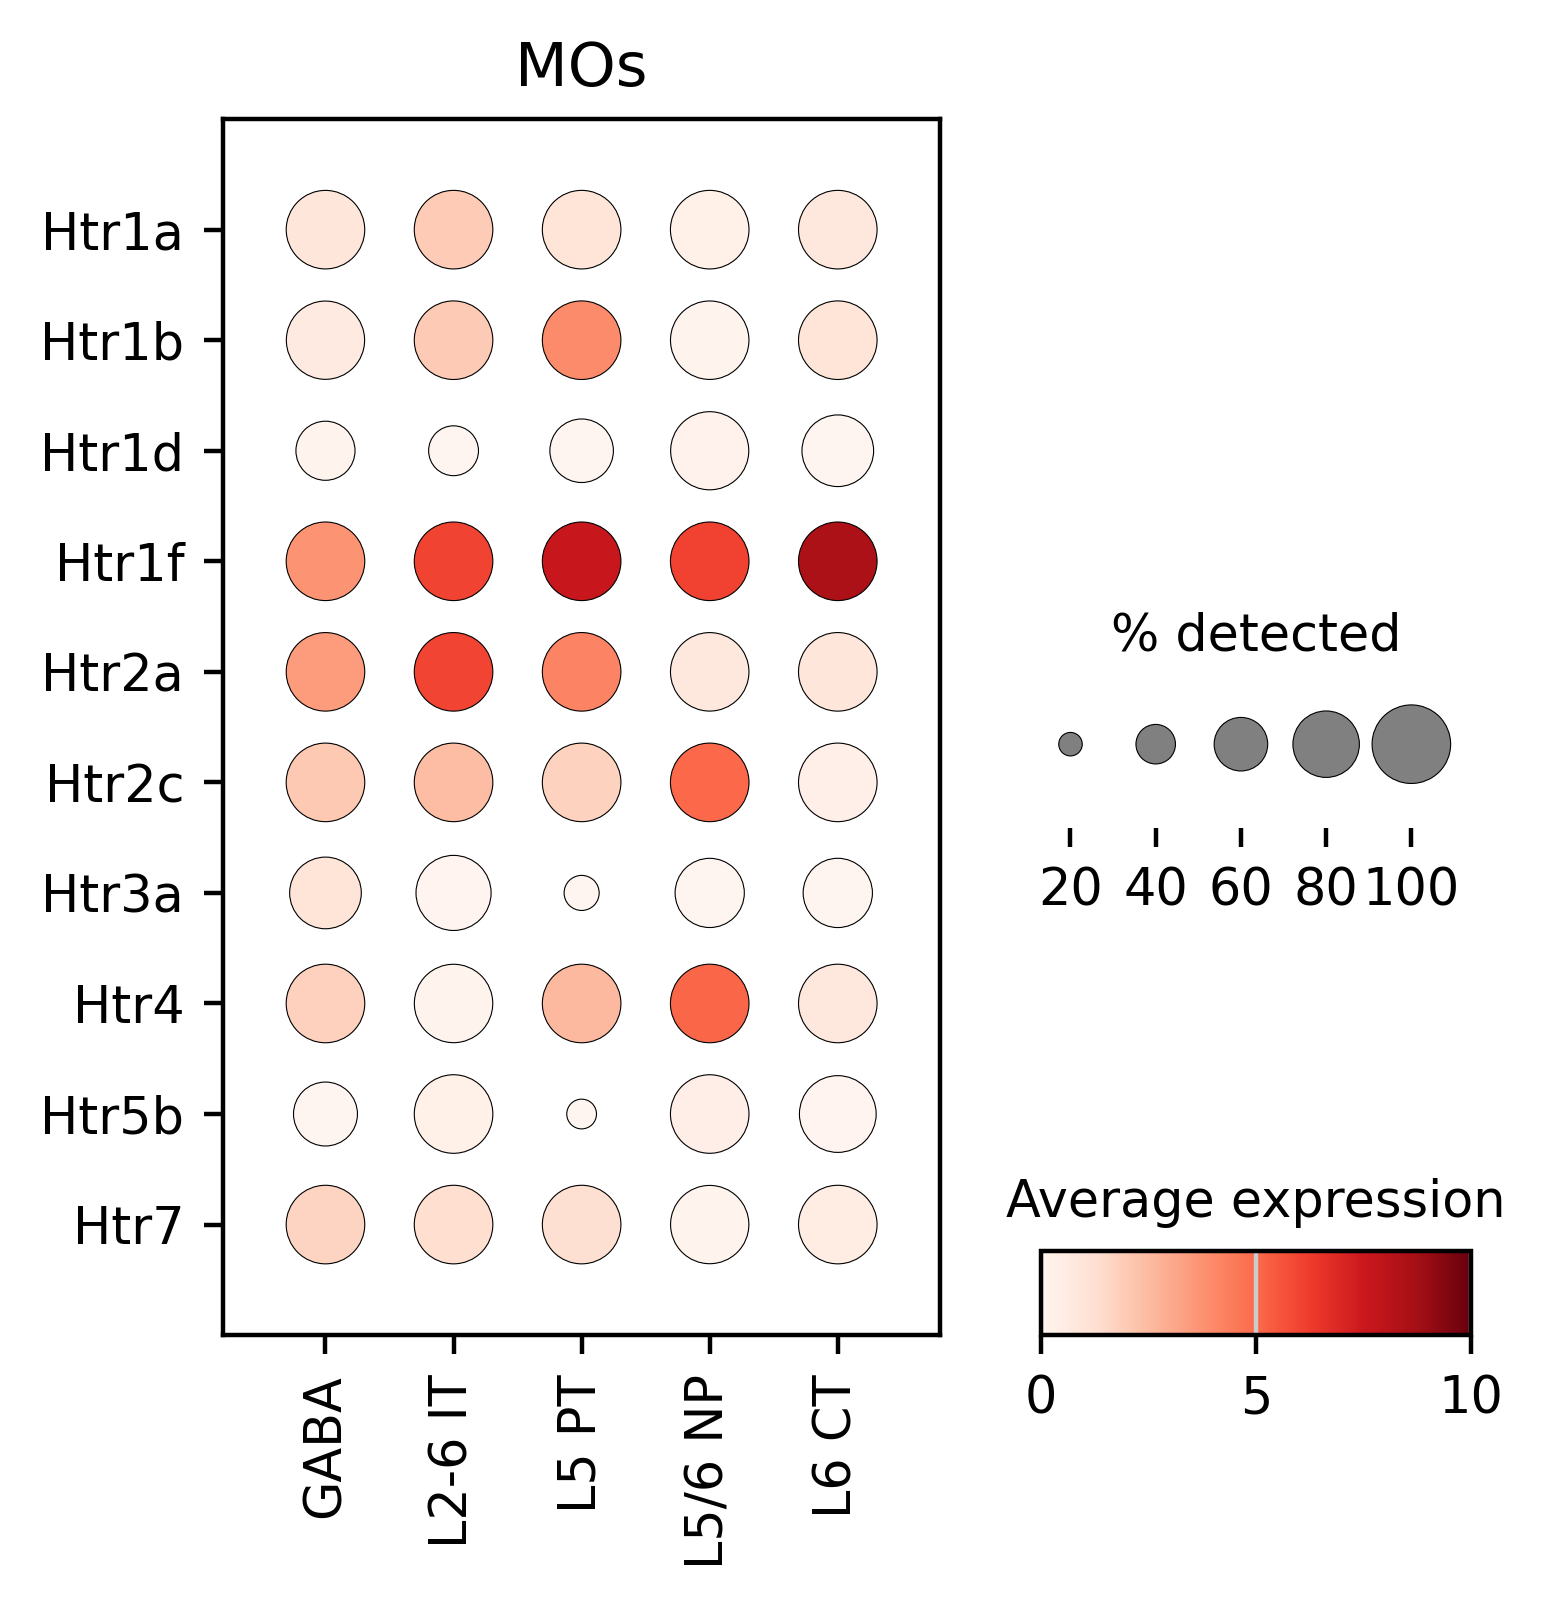

In [ ]:
gaba_subclasses = ['052 Pvalb Gaba', '053 Sst Gaba', '046 Vip Gaba', '049 Lamp5 Gaba', '047 Sncg Gaba']
cellx['subclass'] = cellx['subclass'].replace(gaba_subclasses, 'GABA')

reversed_cell_mapping = {
    '032 L5 NP CTX Glut': 'L5/6 NP',
    '030 L6 CT CTX Glut': 'L6 CT',
    '006 L4/5 IT CTX Glut': 'L2-6 IT',
    '022 L5 ET CTX Glut': 'L5 PT',
    'GABA': 'GABA',
}

# Keeping only neurons
neuronx = cellx.loc[cellx['subclass'].isin(list(reversed_cell_mapping.keys()))].copy()

for r in rois_idx:

    print(r)

    # Get barcodes associated with that brain regions (across all slices)
    idx = rois_idx[r]
    print(len(idx))

    # Subset to only that brain region
    subset = cellx.loc[idx]
    print(subset.shape)

    # Keep only L5 NP nad L5 ET neurons
    subset = subset.merge(neuronx,
                          how='inner',
                          left_index=True,
                          right_index=True)

    print(subset.index[0:5])
    filename = f'{r}_neurons.h5ad'
    adata_subset = adata[subset.index].to_df()
    gdata = anndata.AnnData(adata_subset)
    gdata.obs = subset.copy()
    gdata.var = adata[subset.index].var.copy().set_index('gene_symbol')
    gdata.obs['subclass'] = gdata.obs['subclass_x'].replace(reversed_cell_mapping)

    markers = [
    'Htr1a', 'Htr1b', 'Htr1d', 'Htr1f',
    'Htr2a', 'Htr2c', 'Htr3a', 'Htr4',
    'Htr5b', 'Htr7',
    ]

    gdata.var_names_make_unique()
    sc.settings.set_figure_params(dpi=200, dpi_save=200, fontsize=11)
    sc.pl.dotplot(gdata,
                markers,
                groupby='subclass',
                var_group_rotation = 45.0,
                colorbar_title = 'Average expression',
                size_title = '% detected',
                swap_axes = True,
                vmax = 10, 
                vmin = 0,
                title=r,
                figsize=(4,4),
                dendrogram=False,
                save=f'{r}.svg',
                )

## Sign correction (alignment)

In [ ]:
date = 'October_2025'
sign_df = pd.DataFrame(columns=['PSY', 'SAL']) # DataFrame to store module orientations

# Loop over cell types
for cell_type in cell_types:

    print(cell_type)
    subset_df = gene_exp_df.loc[gene_exp_df.subtype == cell_type]
    genes_df = subset_df[overlap_genes]

    # Encode treatment condition and standardize gene expression
    condition = pd.get_dummies(subset_df.condition, dtype=int)['PSY'].replace(0, -1).to_numpy()
    genes_zscored = StandardScaler().fit_transform(genes_df)

    # Load precomputed PLS model and compute component correlations
    pls = joblib.load(f'{date}/pls_pca/pls_{cell_type}.gz')
    actual_Rs = np.array([pearsonr(X_coef, Y_coef)[0] for X_coef, Y_coef in zip(pls.x_scores_.T, pls.y_scores_.T)])

    # Determine orientation of each component relative to treatment
    for comp, actual_R in enumerate(actual_Rs):
        rho = pearsonr(pls.x_scores_[:, comp], condition)[0]
        module_df = pd.DataFrame(
            data=np.array([float(np.sign(rho)), -1 * float(np.sign(rho)), cell_type, comp]).reshape(1, -1),
            index=[f'{cell_type}_comp_{comp+1}'],
            columns=['PSY', 'SAL', 'cell_type', 'comp']
        )
        sign_df = pd.concat([sign_df, module_df])

# Save signed orientations
sign_df.to_csv(f'{date}/pls_pca/orientation_x.csv')

In [ ]:
# Only look at brain slice corresponding to experiemntal scRNAseq data
section = 'C57BL6J-638850.56'
section_subset = cellx.loc[cellx.brain_section_label==section]
print(section_subset.shape)

# Define path
path = f'abc_atlas/sections/{section}.csv'
if os.path.exists(path):
    pass
else:
    start = time.process_time()

    # Load gene expression based on subset indices
    gdata = adata[section_subset.index, :].to_df()
    print("time taken: ", (time.process_time() - start)/60)

    # Save file
    gdata.to_csv(path)
    print('Saved! \n')

In [ ]:
date = 'October_2025'
    
# Select cells from this brain section
section_subset = cellx.loc[cellx.brain_section_label == section]
print(section_subset.shape)

# Load gene expression data for this section
path = f'abc_atlas/sections/{section}.csv'
start = time.process_time()
gdata = pd.read_csv(path, index_col=0, low_memory=False)
print("time taken to load file: ", (time.process_time() - start)/60, 'min')

# Standardize expression for filtered genes
subset_data = StandardScaler().fit_transform(gdata[gene_filtered.gene_identifier.values])
print(subset_data.shape)
del gdata

for cell_type in tqdm(cell_types):
    # Apply PCA trained on this cell type
    pca = joblib.load(f'{date}/pls_pca/pca_{cell_type}.gz')
    pca_data = pca.transform(subset_data)
    
    # Apply PLS transformation on PCA components
    pls = joblib.load(f'{date}/pls_pca/pls_{cell_type}.gz')
    pls_scores = pls.transform(pca_data)
    
    # Save the transformed scores for this cell type and section
    path = f'abc_atlas/sections/{cell_type}_{section}.npy'
    np.save(path, pls_scores)

print('Done! \n')

In [ ]:
# Invert the sign of PLS components for that specific brain section
# This is to ensure that gene modules scores are aligned with psychedelic treatment
# (higher scores --> more psychedelic-like gene signature)
for cell_type in tqdm(cell_types):
    # Load previously saved PLS scores for this cell type and section
    path = f'abc_atlas/sections/{cell_type}_{section}.npy'
    x_scores = np.load(path)
    
    # Retrieve the sign orientation for this cell type
    sign = sign_df.loc[sign_df.cell_type == cell_type]['PSY'].astype(float).values
    
    # Flip component signs according to reference orientation
    x_flipped = x_scores * sign
    
    # Save the sign-corrected PLS scores
    new_path = f'abc_atlas/sections/flipped/{cell_type}_{section}.npy'
    np.save(new_path, x_flipped)

print('Done! \n')


## Projecting the psilocybin components onto the spatial atlas

In [ ]:
# Set up the normalization and colormap
norm = Normalize(vmin=-2, vmax=2)
cmap = plt.get_cmap('RdBu_r')
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])


# Create a separate figure for the colorbar
fig, ax = plt.subplots(figsize=(0.2, 3), dpi=200)  # Adjust size as needed

# Draw the colorbar
cb = fig.colorbar(sm, cax=ax, orientation='vertical')
cb.set_label('Normalized gene\nmodule score', fontsize=14)
cb.set_ticks([-2, -1, 0, 1, 2])
plt.tick_params(labelsize=12)

# Set colorbar outline color to white
cb.outline.set_edgecolor('white')

# Save the figure
plt.savefig('../../Figures/psilocybin_mouse_pls/colorbar_rd_bu_r.png', dpi=200, bbox_inches='tight', pad_inches=0)
plt.show()
plt.close()


In [ ]:
date = 'October_2025'
section = 'C57BL6J-638850.56'

# Define color normalization for component visualization
norm = Normalize(vmin=-2, vmax=2)

# Loop through subclasses and PLS components to visualize spatial module expression
for sub_class in ['032 L5 NP CTX Glut', '022 L5 ET CTX Glut']:
    for comp in ['Component 1', 'Component 2', 'Component 3']:
        
        row = 0
        fig, ax = plt.subplots(3, 4, figsize=(13, 10), dpi=100)

        # Loop through cell types to generate scatterplots
        for idx, cell_type in enumerate(cell_types):

            # Adjust subplot indices to maintain grid layout
            if ((idx == 4) | (idx == 8)):
                row += 1
                idx = idx - (4 * row)
            elif idx > 3:
                idx = idx - (4 * row)

            section_subset = cellx.loc[cellx.brain_section_label == section]

            # Load precomputed oriented PLS component scores for the section
            path = f'abc_atlas/sections/flipped/{cell_type}_{section}.npy'
            pls_scores = np.load(path, allow_pickle=True)

            # Z-score and format component data
            scores_df = pd.DataFrame(
                StandardScaler().fit_transform(pls_scores[:, 0:3]),
                index=section_subset.index,
                columns=['Component ' + str(col) for col in range(1, 4)]
            )

            # Merge component data with spatial metadata
            joined = scores_df.merge(section_subset, left_index=True, right_index=True)
            comp_df = joined[['x', 'y', 'subclass', comp]].copy()
            comp_df['comp_abs'] = abs(comp_df[comp])

            # Plot background cells in silver and subclass cells with color-coded component values
            sns.scatterplot(
                comp_df.sort_values('comp_abs').loc[comp_df['subclass'] != sub_class],
                x='x', y='y', color='silver', alpha=0.4, ax=ax[row, idx], s=0.2, legend=False
            )
            sns.scatterplot(
                comp_df.sort_values('comp_abs').loc[comp_df['subclass'] == sub_class],
                x='x', y='y', hue=comp, hue_norm=norm, palette='RdBu_r',
                alpha=0.8, ax=ax[row, idx], s=4, legend=False
            )

            # Format subplot appearance
            ax[row, idx].set_title(cell_type, fontsize=20, fontweight='bold')
            ax[row, idx].set_xlim(1.75, 9.6)
            ax[row, idx].set_ylim(8.5, 2.5)
            ax[row, idx].axis('off')

        # Remove unused panels in the bottom row
        fig.delaxes(ax[2, 3])
        fig.delaxes(ax[2, 2])

        # Save figure for each component and subclass
        plt.suptitle(f'{comp}: {sub_class}', fontsize=30, fontweight='bold', y=1.03)
        plt.tight_layout()
        plt.savefig(
            f'../../Figures/psilocybin_mouse_pls/{comp}_{sub_class.replace("/", "_")}.tiff',
            dpi=200, bbox_inches='tight'
        )
        plt.close('all')


## Quantifying overlap between receptor expression and gene module scores

In [9]:
# Takes 1 min to run
# This is the brain section that best correspond the experimental dataset
section = 'C57BL6J-638850.56'
print(section)
section_subset = cellx.loc[cellx.brain_section_label==section]
print(section_subset.shape)
path = f'abc_atlas/sections/{section}.csv'
start = time.process_time()
gdata = pd.read_csv(path, index_col=0, low_memory=False)
subset_data = gdata[gene_filtered.gene_identifier.values]
subset_data.columns = gene_filtered.index
print(subset_data.shape)
subset_data = subset_data.reset_index()
del gdata

C57BL6J-638850.56
(57175, 20)
(57175, 8264)


### Plotting gene expresson on brain slices (2D maps)

In [ ]:
# Define genes to plot
genes_to_plot = ['Ntrk2', 'Ahr']
section = 'C57BL6J-638850.56'
norm = Normalize(vmin=0, vmax=10)

# Subset and merge
section_subset = cellx.loc[cellx.brain_section_label == section].reset_index()
section_subset['cell_label'] = section_subset['cell_label'].astype(int)
joined = subset_data.merge(section_subset, on='cell_label')

# Prepare data for plotting
cols = genes_to_plot + ['x', 'y']
comp_df = joined[cols].copy()

# Set up figure layout
nrows, ncols = 1, len(genes_to_plot)
fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(8, 4), dpi=100)

# Ensure `ax` is iterable even if there’s only one plot
if ncols == 1:
    ax = [ax]

# Plot each gene
for i, gene in enumerate(genes_to_plot):
    sns.scatterplot(
        data=comp_df, x='x', y='y', hue=gene, hue_norm=norm,
        palette='magma_r', alpha=0.8, ax=ax[i], s=2, legend=False
    )
    ax[i].set_title(gene, fontsize=14, fontweight='bold')
    ax[i].set_xlim(1.75, 9.6)
    ax[i].set_ylim(8.5, 2.5)
    ax[i].axis('off')

plt.suptitle(
    'Spatial distribution of Ntrk2 and Ahr expression',
    fontsize=20, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig('../../Figures/psilocybin_mouse_pls/spatial_ntrk2_ahr.tiff', bbox_inches='tight', dpi=200)
plt.show()
plt.close('all')


In [ ]:
# Define serotonin receptor genes to visualize
genes_to_plot = [
    'Htr1a', 'Htr1b', 'Htr1d', 'Htr1f',
    'Htr2a', 'Htr2c', 'Htr3a', 'Htr4',
    'Htr5b', 'Htr7',
]

section = 'C57BL6J-638850.56'

# Set normalization for color scaling across plots
norm = Normalize(vmin=0, vmax=10)

# Subset cell metadata for the brain section of interest
section_subset = cellx.loc[cellx.brain_section_label == section].reset_index()
section_subset['cell_label'] = section_subset['cell_label'].astype(int)

# Merge gene expression data with spatial coordinates
joined = subset_data.merge(section_subset, on='cell_label')

# Prepare DataFrame containing gene expression and spatial information
cols = genes_to_plot.copy() + ['x', 'y']
comp_df = joined[cols].copy()

# Set up grid for spatial gene expression plots
nrows, ncols = 2, 5
fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 6), dpi=100)
genes = genes_to_plot.copy()

# Loop through genes and plot their spatial expression pattern
for i, gene in tqdm(enumerate(genes)):
    row_idx = i // ncols
    col_idx = i % ncols

    sns.scatterplot(
        data=comp_df, x='x', y='y', hue=gene, hue_norm=norm,
        palette='magma_r', alpha=0.8, ax=ax[row_idx, col_idx], s=2, legend=False
    )

    # Format subplot appearance
    ax[row_idx, col_idx].set_title(gene, fontsize=14, fontweight='bold')
    ax[row_idx, col_idx].set_xlim(1.75, 9.6)
    ax[row_idx, col_idx].set_ylim(8.5, 2.5)
    ax[row_idx, col_idx].axis('off')

# Add overall title and save figure
plt.suptitle(
    'A. Spatial distribution of serotonin receptor and non-serotonin receptor expression (Yao et al.)',
    fontsize=20, fontweight='bold', y=1
)
plt.tight_layout()
plt.savefig('../../Figures/psilocybin_mouse_pls/spatial_sero.tiff', dpi=200, bbox_inches='tight')
plt.show()
plt.close('all')


In [ ]:
# Create a separate figure for the horizontal colorbar
fig, ax = plt.subplots(figsize=(5, 0.2), dpi=100)  # Wide and short

# Create a scalar mappable
cmap = mpl.colormaps['magma_r']
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

# Draw the horizontal colorbar
cbar = fig.colorbar(sm, cax=ax, orientation='horizontal')
cbar.set_label('Log-normalized expression', fontsize=12, labelpad=5)
cbar.outline.set_edgecolor('white')

plt.savefig(f'../../Figures/psilocybin_mouse_pls/sero_spatial_colorbar_horizontal.svg', dpi=200, bbox_inches='tight')
plt.show()
plt.close()

In [ ]:
# Define brain section and visualization parameters
section = 'C57BL6J-638850.56'
row = 0
norm = Normalize(vmin=0, vmax=10)

# Subset metadata for the selected brain section
section_subset = cellx.loc[cellx.brain_section_label == section].reset_index()
section_subset['cell_label'] = section_subset['cell_label'].astype(int)

# Merge spatial metadata with gene expression data
joined = subset_data.merge(section_subset, on='cell_label')

# Select relevant serotonin receptor genes and spatial coordinates
cols = [gene.capitalize() for gene in sero_genes_over]
cols += ['x', 'y', 'subclass']
comp_df = joined[cols].copy()

# Loop over the selected cell subclasses to visualize gene expression
for cell_type in np.unique(['032 L5 NP CTX Glut', '022 L5 ET CTX Glut']):
    print(cell_type)
    
    # Initialize subplot grid for 3x3 gene expression maps
    fig, ax = plt.subplots(3, 3, dpi=100)
    fig.set_size_inches(10, 10)

    row = 0
    for idx, gene in tqdm(enumerate([gene.capitalize() for gene in sero_genes_over])):
        # Determine subplot position
        if (idx == 3) | (idx == 6):
            row += 1
            idx = idx - (3 * row)
        elif idx > 2:
            idx = idx - (3 * row)
        else:
            idx = idx

        # Plot background cells in grey
        sns.scatterplot(
            comp_df.loc[comp_df['subclass'] != cell_type],
            x='x', y='y',
            color='silver', alpha=0.4,
            ax=ax[row, idx], s=0.2, legend=False
        )

        # Overlay expression of current gene in the target cell subclass
        sns.scatterplot(
            comp_df.loc[comp_df['subclass'] == cell_type],
            x='x', y='y',
            hue=gene, hue_norm=norm,
            palette='magma_r', alpha=0.8,
            ax=ax[row, idx], s=4, legend=False
        )

        # Customize subplot appearance
        ax[row, idx].set_title(gene, fontsize=20, fontweight='bold')
        ax[row, idx].set_xlim(1.75, 9.6)
        ax[row, idx].set_ylim(8.5, 2.5)
        ax[row, idx].set_xticks([])
        ax[row, idx].set_yticks([])
        ax[row, idx].spines[:].set_visible(False)
        ax[row, idx].axis('off')

    # Add figure title and save plot
    plt.suptitle(f'Serotonin receptors expression: {cell_type}', fontsize=30, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.savefig(f'../../Figures/psilocybin_mouse_pls/sero_{cell_type}.tiff', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close('all')


In [ ]:
# Create a separate figure for the colorbar
fig, ax = plt.subplots(figsize=(0.2, 3), dpi=100)  # Adjust size as needed

# Create a scalar mappable with the same norm and colormap
cmap = mpl.colormaps['magma_r']
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])  # Dummy data for ScalarMappable

# Draw the colorbar
cbar = fig.colorbar(sm, cax=ax, orientation='vertical')
cbar.set_label('Log-normalized expression', fontsize=12)
cbar.outline.set_edgecolor('white')

plt.savefig(f'../../Figures/psilocybin_mouse_pls/sero_spatial_colorbar_vertical.svg', dpi=200, bbox_inches='tight')
plt.show()
plt.close()

### Plotting average receptor expression (barplots and regression models)

In [30]:
section_subset = cellx.loc[cellx.brain_section_label == section].reset_index()
section_subset['cell_label'] = section_subset['cell_label'].astype(int)
joined = subset_data.merge(section_subset, on='cell_label')
sero = [gene.capitalize() for gene in sero_mouse]

gaba_subclasses = ['052 Pvalb Gaba', '053 Sst Gaba', '046 Vip Gaba', '049 Lamp5 Gaba', '047 Sncg Gaba']
joined['subclass'] = joined['subclass'].replace(gaba_subclasses, 'GABA')

cell_mapping = {
    'L5-6_NP': '032 L5 NP CTX Glut',
    'L6_CT': '030 L6 CT CTX Glut',
    'L2-5_IT': '006 L4/5 IT CTX Glut',  # better match than '007 L2/3 IT CTX Glut'
    'L5_PT': '022 L5 ET CTX Glut',
    'Oligo': '327 Oligo NN',
    'OPC': '326 OPC NN',
    'NFO': '326 OPC NN',  # same label, different embeddings
    'GABA': 'GABA',
    'Micro': '334 Microglia NN',
    'Astro': '319 Astro-TE NN',
    'Endo': '333 Endo NN',
}

reversed_cell_mapping = {
    '032 L5 NP CTX Glut': 'L5/6 NP',
    '030 L6 CT CTX Glut': 'L6 CT',
    '006 L4/5 IT CTX Glut': 'L2-6 IT',
    '022 L5 ET CTX Glut': 'L5 PT',
    'GABA': 'GABA',
    '327 Oligo NN': 'Oligo',
    '326 OPC NN': 'OPC',  # 'NFO' overwrites 'OPC'
    '334 Microglia NN': 'Micro',
    '319 Astro-TE NN':'Astro',
    '333 Endo NN': 'Endo',
}


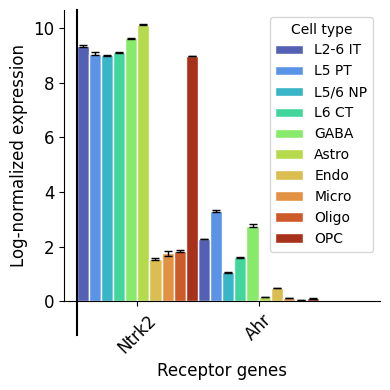

In [31]:
# Genes to plot
genes_to_plot = ['Ntrk2', 'Ahr']

# Compute grouped statistics
grouped = joined.groupby('subclass')[genes_to_plot].agg(['mean', 'std', 'count']).reset_index()

# Flatten MultiIndex columns
grouped.columns = ['_'.join(col).strip('_') for col in grouped.columns.values]

# Map and clean subtype labels
grouped = grouped.set_index('subclass', drop=False).loc[cell_mapping.values()]
grouped['subclass'] = grouped['subclass'].map(reversed_cell_mapping)
grouped = grouped.drop_duplicates().reset_index(drop=True)
grouped = grouped.sort_values(by='subclass')

# Prepare long-format data
mean_cols = [col for col in grouped.columns if col.endswith('mean')]
std_cols = [col for col in grouped.columns if col.endswith('std')]
count_cols = [col for col in grouped.columns if col.endswith('count')]

df_mean = grouped.melt(id_vars='subclass', value_vars=mean_cols, var_name='Gene', value_name='Mean')
df_mean['Gene'] = df_mean['Gene'].str.replace('_mean', '').str.capitalize()

df_std = grouped.melt(id_vars='subclass', value_vars=std_cols, var_name='Gene', value_name='Std')
df_std['Gene'] = df_std['Gene'].str.replace('_std', '').str.capitalize()

df_count = grouped.melt(id_vars='subclass', value_vars=count_cols, var_name='Gene', value_name='Count')
df_count['Gene'] = df_count['Gene'].str.replace('_count', '').str.capitalize()

# Merge all
df_all = df_mean.merge(df_std, on=['subclass', 'Gene'])
df_all = df_all.merge(df_count, on=['subclass', 'Gene'])
df_all = df_all.rename(columns={'subclass': 'Cell type'})

# Cell type order (must match hue_order)
order = [
    'L2-6 IT',
    'L5 PT',
    'L5/6 NP',
    'L6 CT',
    'GABA',
    'Astro',
    'Endo',
    'Micro',
    'Oligo',
    'OPC'
]

# Compute 95% CI error bars
z = 1.96
df_all['yerr'] = z * (df_all['Std'] / np.sqrt(df_all['Count']))

# Compute 95% confidence intervals
df_all['CI_lower'] = df_all['Mean'] - df_all['yerr']
df_all['CI_upper'] = df_all['Mean'] + df_all['yerr']

# Select relevant columns for display
ci_summary = df_all[['Gene', 'Cell type', 'Mean', 'CI_lower', 'CI_upper']].copy()

# Round for readability
ci_summary = ci_summary.round(3)

# Save results
ci_summary.to_csv(f'October_2025/Yao_mean_non_sero_expression_CI.csv')

# Plot
plt.figure(figsize=(4, 4), dpi=100)
ax = sns.barplot(
    data=df_all, x='Gene', y='Mean', hue='Cell type',
    hue_order=order, palette='turbo', ci=None,
    width=1, linewidth=1, edgecolor="white"
)

ax.spines[['right', 'top']].set_visible(False)
ax.set_ylabel('Log-normalized expression', fontsize=12)

# Correctly position error bars
n_genes = len(df_all['Gene'].unique())
n_cell_types = len(order)
gene_order = df_all['Gene'].unique()
group_width = 1
bar_width = group_width / n_cell_types

for j, gene in enumerate(gene_order):
    for k, cell in enumerate(order):
        subset = df_all[(df_all['Gene'] == gene) & (df_all['Cell type'] == cell)]
        if not subset.empty:
            x = j + (k - (n_cell_types - 1) / 2) * bar_width
            y = subset['Mean'].values[0]
            yerr = subset['yerr'].values[0]
            ax.errorbar(x=x, y=y, yerr=yerr, fmt='none', c='black', capsize=3, linewidth=1)

# Add vertical divider between genes
line_x = len(gene_order) - 2 - 0.5
ax.axvline(x=line_x, color='black', linestyle='-', linewidth=1.5, clip_on=False, ymin=-0.115)

# Formatting
plt.xlim(-0.6, 2)
plt.xticks(rotation=45, size=12)
plt.xlabel('Receptor genes', fontsize=12)
plt.yticks(size=12)
plt.tight_layout()
plt.savefig('../../Figures/psilocybin_mouse_pls/gene_exp_Ntrk2_Ahr_95_CI.svg', bbox_inches='tight', dpi=200)
plt.show()


In [32]:
ci_summary

,Gene,Cell type,Mean,CI_lower,CI_upper
0,Ntrk2,Astro,10.135,10.109,10.160
1,Ntrk2,Endo,1.558,1.526,1.590
2,Ntrk2,GABA,9.638,9.619,9.658
3,Ntrk2,L2-6 IT,9.356,9.329,9.383
4,Ntrk2,L5 PT,9.067,9.015,9.118
5,Ntrk2,L5/6 NP,9.003,8.978,9.027
6,Ntrk2,L6 CT,9.120,9.101,9.140
7,Ntrk2,Micro,1.762,1.677,1.848
8,Ntrk2,OPC,8.993,8.984,9.001
9,Ntrk2,Oligo,1.834,1.796,1.872


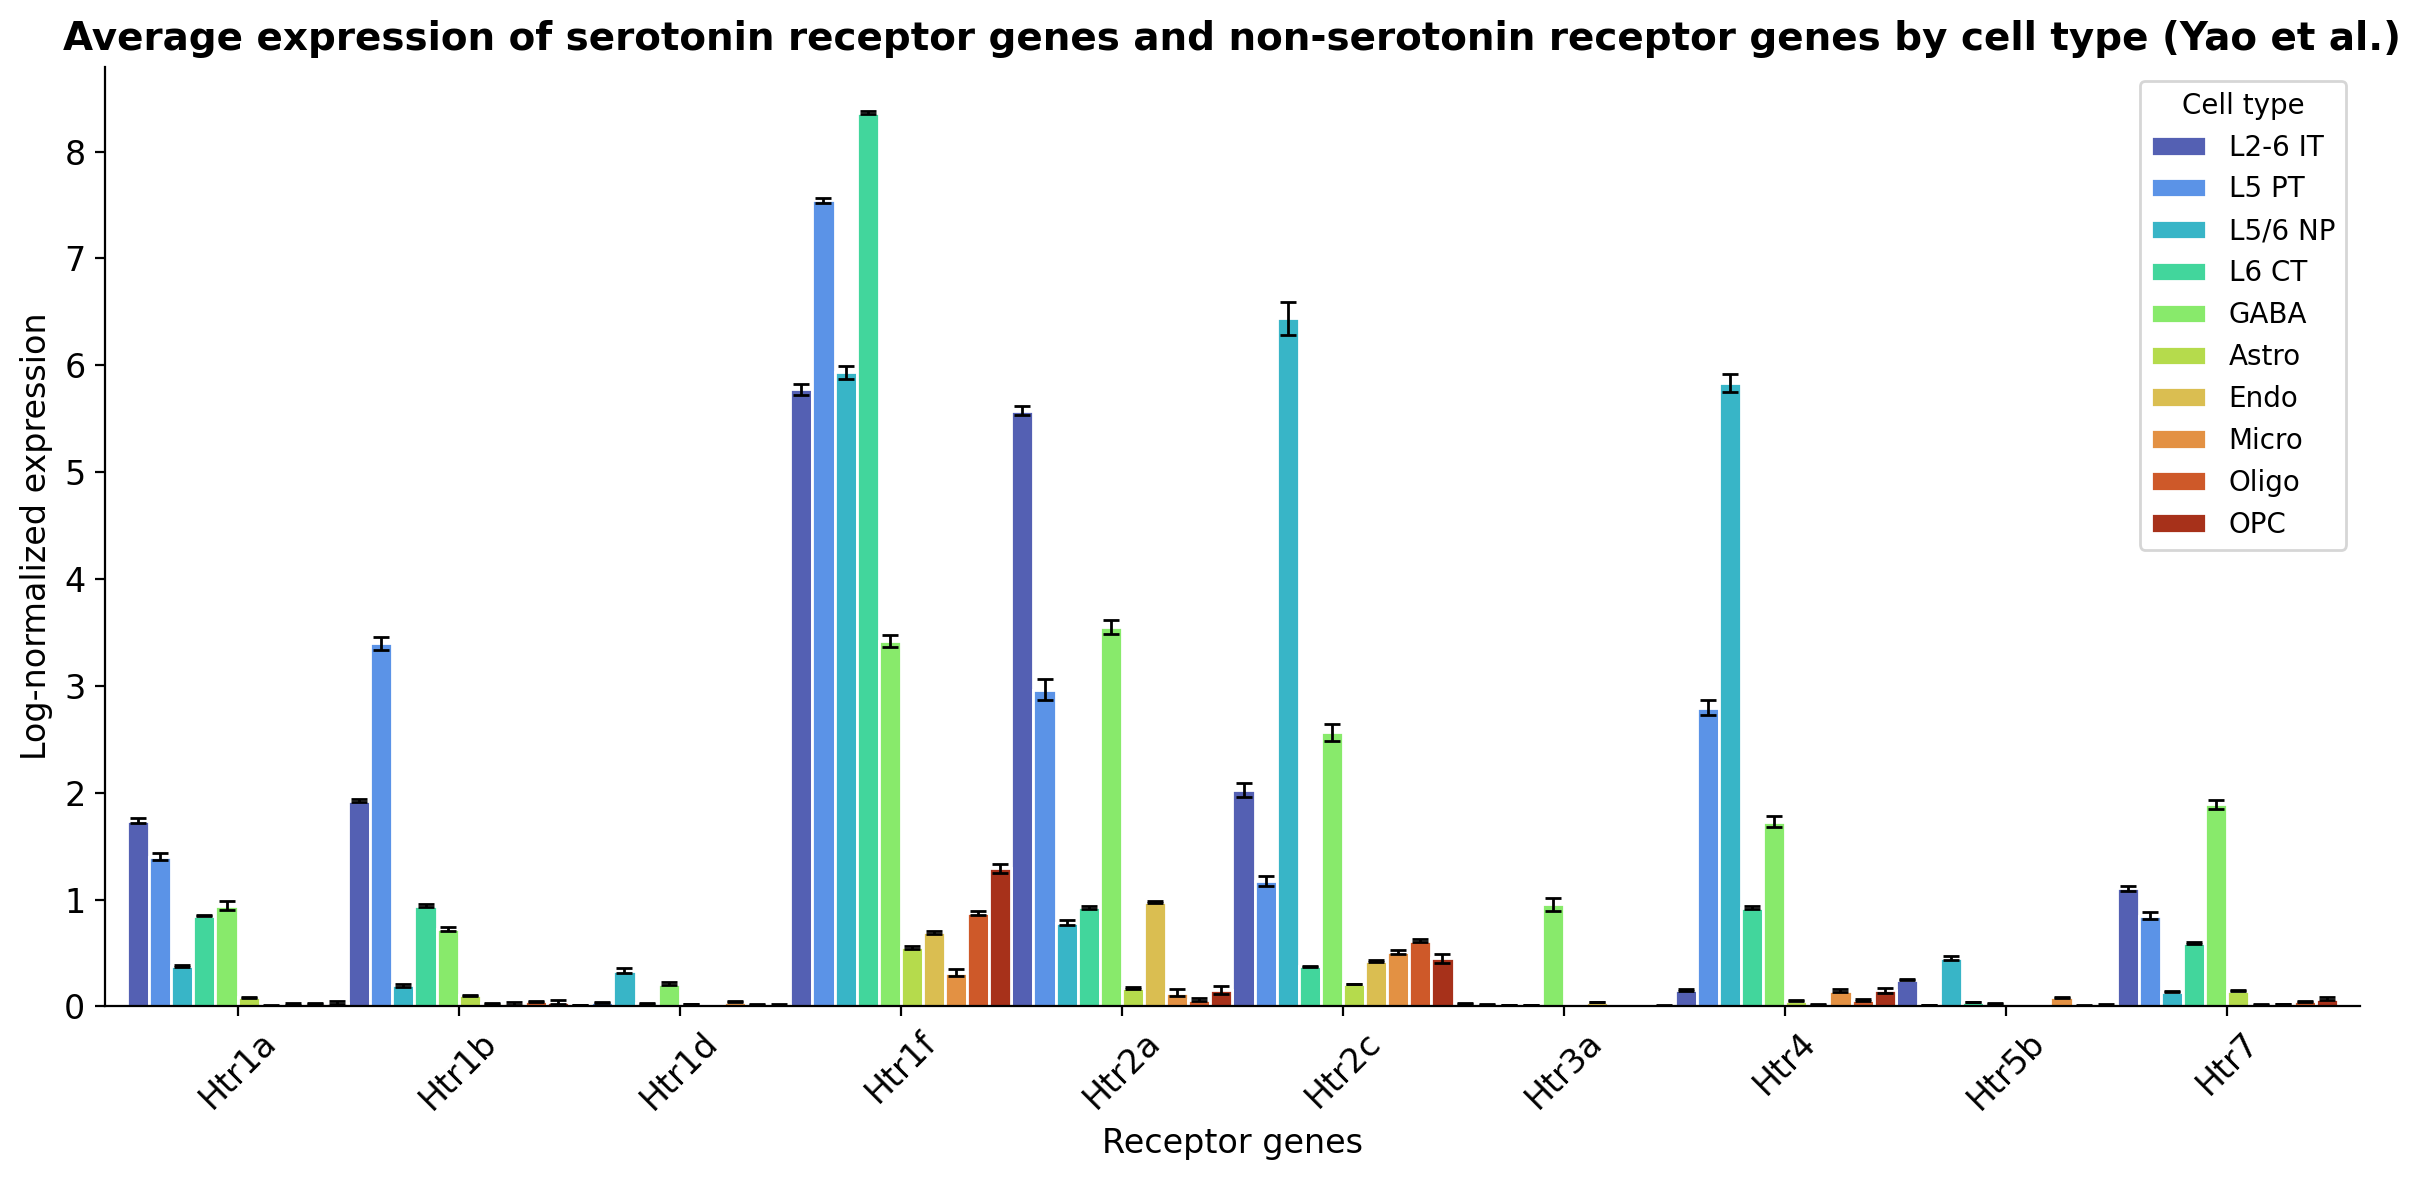

In [33]:
# --- Group stats: mean, std, count ---
grouped = joined.groupby('subclass')[sero].agg(['mean', 'std', 'count']).reset_index()

# Selecting corresponding cell types
grouped = grouped.set_index('subclass', drop=False).loc[cell_mapping.values()]
grouped['subclass'] = grouped['subclass'].map(reversed_cell_mapping)
grouped = grouped.drop_duplicates().reset_index(drop=True)
grouped = grouped.sort_values(by='subclass')

# Flatten MultiIndex columns
grouped.columns = ['_'.join(col).strip('_') for col in grouped.columns.values]

# Subtype labels
grouped['subtype_'] = grouped['subclass']

# --- Prepare long format with mean, std, and count ---
mean_cols = [col for col in grouped.columns if col.endswith('mean')]
std_cols = [col for col in grouped.columns if col.endswith('std')]
count_cols = [col for col in grouped.columns if col.endswith('count')]

# Melt mean
df_mean = grouped.melt(id_vars='subtype_', value_vars=mean_cols,
                       var_name='Gene', value_name='Mean')
df_mean['Gene'] = df_mean['Gene'].str.replace('_mean', '').str.capitalize()

# Melt std
df_std = grouped.melt(id_vars='subtype_', value_vars=std_cols,
                      var_name='Gene', value_name='Std')
df_std['Gene'] = df_std['Gene'].str.replace('_std', '').str.capitalize()

# Melt count
df_count = grouped.melt(id_vars='subtype_', value_vars=count_cols,
                        var_name='Gene', value_name='Count')
df_count['Gene'] = df_count['Gene'].str.replace('_count', '').str.capitalize()

# Merge all
df_all = df_mean.merge(df_std, on=['subtype_', 'Gene'])
df_all = df_all.merge(df_count, on=['subtype_', 'Gene'])
df_all = df_all.rename(columns={'subtype_': 'Cell type'})

# --- 95% Confidence Interval ---
z = 1.96  # z-score for 95% CI
df_all['yerr'] = z * (df_all['Std'] / np.sqrt(df_all['Count']))

# Compute 95% confidence intervals
df_all['CI_lower'] = df_all['Mean'] - df_all['yerr']
df_all['CI_upper'] = df_all['Mean'] + df_all['yerr']

# Select relevant columns for display
ci_summary = df_all[['Gene', 'Cell type', 'Mean', 'CI_lower', 'CI_upper']].copy()

# Round for readability
ci_summary = ci_summary.round(3)
# Save results
ci_summary.to_csv(f'October_2025/Yao_mean_sero_expression_CI.csv')

# --- Plot ---
plt.figure(figsize=(12, 6), dpi=200)
ax = sns.barplot(
    data=df_all, x='Gene', y='Mean', hue='Cell type',
    hue_order=order, palette='turbo',
    ci=None, width=1, linewidth=1, edgecolor="white"
)

ax.spines[['right', 'top']].set_visible(False)
ax.set_ylabel('Log-normalized expression', fontsize=12)

# --- Correct error bar placement ---
n_genes = len(df_all['Gene'].unique())
n_cell_types = len(order)
gene_order = df_all['Gene'].unique()
group_width = 1
bar_width = group_width / n_cell_types

for j, gene in enumerate(gene_order):                # iterate over genes, not cell types
    for k, cell in enumerate(order):                 # consistent hue order
        subset = df_all[(df_all['Gene'] == gene) & (df_all['Cell type'] == cell)]
        if not subset.empty:
            x = j + (k - (n_cell_types - 1) / 2) * bar_width
            y = subset['Mean'].values[0]
            yerr = subset['yerr'].values[0]
            ax.errorbar(x=x, y=y, yerr=yerr, fmt='none', c='black', capsize=3, linewidth=1)

# --- Aesthetics ---
plt.xlim(-0.6, len(gene_order) - 0.4)
plt.xlabel('Receptor genes', fontsize=12)
plt.xticks(rotation=45, size=12)
plt.yticks(size=12)
plt.title(
    'Average expression of serotonin receptor genes and non-serotonin receptor genes by cell type (Yao et al.)',
    fontweight='bold', fontsize=14
)
plt.tight_layout()
#plt.savefig('../../Figures/psilocybin_mouse_pls/gene_exp_sero_Yao_95_CI.svg', bbox_inches='tight', dpi=200)
plt.show()


In [35]:
df_mean

,subtype_,Gene,Mean
0,Astro,Htr1a,0.084313
1,Endo,Htr1a,0.008511
2,GABA,Htr1a,0.942292
3,L2-6 IT,Htr1a,1.737945
4,L5 PT,Htr1a,1.403042
...,...,...,...
95,L5/6 NP,Htr7,0.138027
96,L6 CT,Htr7,0.594462
97,Micro,Htr7,0.024314
98,OPC,Htr7,0.074231


In [14]:
ci_summary.loc[ci_summary.Gene=='Htr2a']

,Gene,Cell type,Mean,CI_lower,CI_upper
40,Htr2a,Astro,0.172,0.159,0.185
41,Htr2a,Endo,0.981,0.972,0.991
42,Htr2a,GABA,3.554,3.487,3.620
43,Htr2a,L2-6 IT,5.573,5.531,5.615
44,Htr2a,L5 PT,2.963,2.864,3.061
45,Htr2a,L5/6 NP,0.785,0.758,0.812
46,Htr2a,L6 CT,0.927,0.910,0.943
47,Htr2a,Micro,0.127,0.095,0.159
48,Htr2a,OPC,0.151,0.114,0.188
49,Htr2a,Oligo,0.064,0.047,0.080


In [15]:
ci_summary.loc[ci_summary.Gene=='Htr1f']

,Gene,Cell type,Mean,CI_lower,CI_upper
30,Htr1f,Astro,0.554,0.538,0.570
31,Htr1f,Endo,0.695,0.682,0.708
32,Htr1f,GABA,3.419,3.359,3.480
33,Htr1f,L2-6 IT,5.775,5.721,5.829
34,Htr1f,L5 PT,7.542,7.517,7.566
35,Htr1f,L5/6 NP,5.936,5.876,5.997
36,Htr1f,L6 CT,8.361,8.347,8.375
37,Htr1f,Micro,0.316,0.281,0.351
38,Htr1f,OPC,1.295,1.253,1.337
39,Htr1f,Oligo,0.877,0.859,0.895


In [16]:
ci_summary.loc[ci_summary.Gene=='Htr2c']

,Gene,Cell type,Mean,CI_lower,CI_upper
50,Htr2c,Astro,0.211,0.209,0.213
51,Htr2c,Endo,0.428,0.419,0.436
52,Htr2c,GABA,2.564,2.485,2.642
53,Htr2c,L2-6 IT,2.026,1.964,2.088
54,Htr2c,L5 PT,1.174,1.123,1.225
55,Htr2c,L5/6 NP,6.439,6.285,6.594
56,Htr2c,L6 CT,0.375,0.372,0.379
57,Htr2c,Micro,0.509,0.486,0.532
58,Htr2c,OPC,0.451,0.411,0.492
59,Htr2c,Oligo,0.614,0.599,0.630


In [17]:
cols = [gene.capitalize() for gene in sero_genes_over]
receptor_list = [gene.capitalize() for gene in sero_mouse]
receptor_list.append('Ntrk2')
receptor_list.append('Ahr')

In [18]:
cell_mapping = {
    'L2-5_IT': '006 L4/5 IT CTX Glut',
    'L5_PT': '022 L5 ET CTX Glut',
    'L5-6_NP': '032 L5 NP CTX Glut',
    'L6_CT': '030 L6 CT CTX Glut',
    'GABA': 'GABA',
    'Astro': '319 Astro-TE NN',
    'Endo': '333 Endo NN',
    'Micro': '334 Microglia NN',
    'Oligo': '327 Oligo NN',
    'OPC': '326 OPC NN',
}

In [19]:
sorted_mapping = dict(sorted(cell_mapping.items()))
print(sorted_mapping)

{'Astro': '319 Astro-TE NN', 'Endo': '333 Endo NN', 'GABA': 'GABA', 'L2-5_IT': '006 L4/5 IT CTX Glut', 'L5-6_NP': '032 L5 NP CTX Glut', 'L5_PT': '022 L5 ET CTX Glut', 'L6_CT': '030 L6 CT CTX Glut', 'Micro': '334 Microglia NN', 'OPC': '326 OPC NN', 'Oligo': '327 Oligo NN'}


In [20]:
# Get the list of unique subclasses from the cell mapping
sub_classes = list(cell_mapping.values())
section = 'C57BL6J-638850.56'

# Dictionary to store oriented PLS component scores for each cell class
class_dict = {}
for cell_class in tqdm(sub_classes):
    comp_dict = {}
    for idx, cell_type in enumerate(cell_types):
        # Subset cells for the current brain section
        section_subset = cellx.loc[cellx.brain_section_label == section]
        # Merge GABA subclasses into a single label
        section_subset.loc[section_subset['subclass'].isin(gaba_subclasses), 'subclass'] = 'GABA'

        # Load flipped PLS component scores (aligned such that higher scores = more psilocybin-like)
        path = f'abc_atlas/sections/flipped/{cell_type}_{section}.npy'
        pls_scores = np.load(path, allow_pickle=True)

        # Standardize component scores and store in a DataFrame
        scores_df = pd.DataFrame(
            StandardScaler().fit_transform(pls_scores[:, 0:3]),
            index=section_subset.index,
            columns=['Component ' + str(col) for col in range(1, 4)]
        )

        # Merge component scores with subclass labels
        class_subset = scores_df.reset_index().merge(section_subset[['subclass']].reset_index(), on='cell_label')
        comp_dict[f'{cell_type}'] = class_subset.loc[class_subset['subclass']==cell_class].copy()

    class_dict[f'{cell_class}'] = comp_dict


# Prepare receptor expression data for regression
section_subset = cellx.loc[cellx.brain_section_label == section].reset_index()
section_subset['cell_label'] = section_subset['cell_label'].astype(int)
joined = subset_data.merge(section_subset, on='cell_label')
# Combine GABA subclasses
joined['subclass'] = joined['subclass'].replace(gaba_subclasses, 'GABA')

# Select receptor genes and additional genes to include
cols = receptor_list.copy()
cols.append('Gfral')
cols.append('Tgfbr1')

# Standardize expression of selected genes
for gene in cols:
    joined[gene] = StandardScaler().fit_transform(joined[gene].values.reshape(-1, 1))

# Add subclass and cell label for downstream merging
cols.append('subclass')
cols.append('cell_label')

# Create final DataFrame for receptor expression
comp_df = joined[cols].copy()

# Dictionary to store receptor expression data for each subclass
recep_dict = {}

for cell_type in sub_classes:
    print(cell_type)
    # Subset receptor expression for the current subclass
    cell_df = comp_df.loc[comp_df['subclass']==cell_type].copy()
    recep_dict[cell_type] = cell_df


100%|██████████| 10/10 [00:27<00:00,  2.76s/it]


006 L4/5 IT CTX Glut
022 L5 ET CTX Glut
032 L5 NP CTX Glut
030 L6 CT CTX Glut
GABA
319 Astro-TE NN
333 Endo NN
334 Microglia NN
327 Oligo NN
326 OPC NN


Serotonin receptor expressions

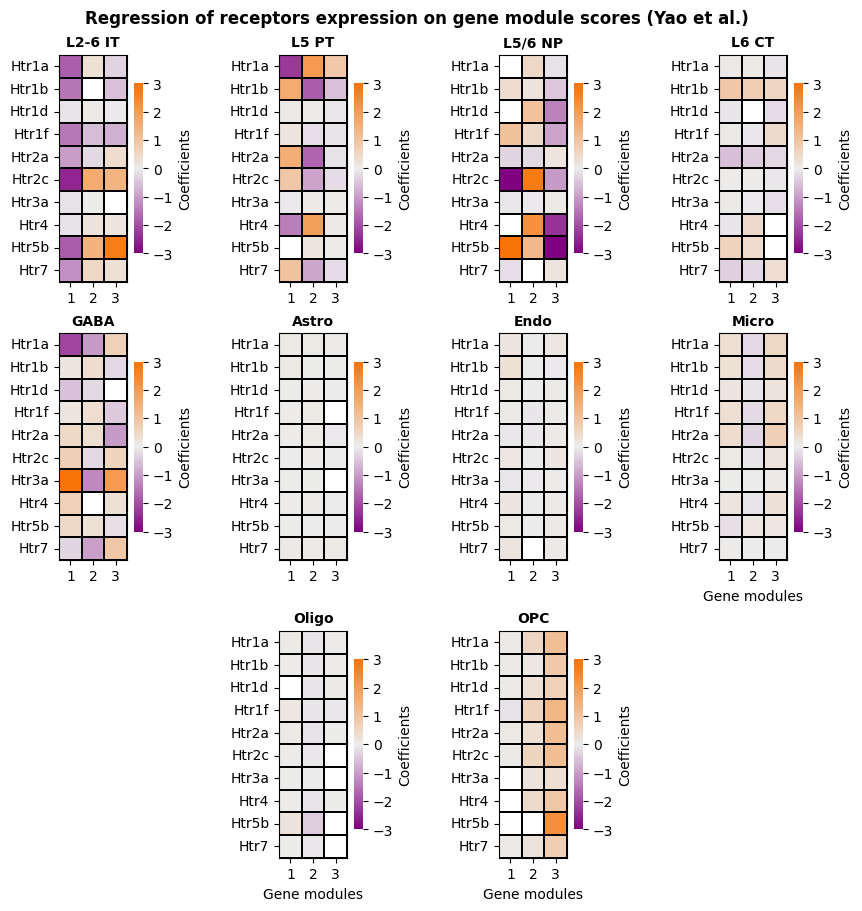

In [ ]:
import statsmodels.api as sm

# Define a custom diverging color palette (purple → neutral beige → orange)
custom_colors = [
    "#800080",  # Purple (negative coefficients)
    "#110909",  # Neutral beige (zero-centered)
    "#F97306",  # Orange (positive coefficients)
]

# Create the continuous color map
custom_map = mcolors.LinearSegmentedColormap.from_list("purple_orange", custom_colors, N=256)

# Prepare receptor and component column names
receptor_list = [gene.capitalize() for gene in sero_mouse]
cols = receptor_list.copy()
comp_cols = ['Component ' + str(col) for col in range(1, 4)]

# Define grid layout for visualization
n_cell_types = len(cell_types)
n_cols = 4
n_rows = 3

fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.2 * n_cols, 3 * n_rows), constrained_layout=True, dpi=100)
axes = axes.flatten()

# Add component names to the columns list for later merging
for comp in comp_cols:
    cols.append(comp)

# Store all coefficients in p-values in a dictionary
all_coefs = {}

# Loop through each cell type and its corresponding subclass
for i, (cell_type, cell_class) in enumerate(cell_mapping.items()):

    # Adjust index for empty subplots (to maintain visual layout)
    if i == 8:
        i = 9
    elif i == 9:
        i = 10

    # Get receptor and PLS component data for the given cell class
    sero_values = recep_dict[cell_class]
    comp_values = class_dict[cell_class][cell_type]
    comp_values['cell_label'] = comp_values.cell_label.astype(int)

    # Merge receptor expression with PLS component scores
    test_df = sero_values.merge(comp_values, on='cell_label')[cols].copy()

    # Initialize DataFrames to store regression coefficients and p-values
    coefs_df = pd.DataFrame()
    pvals_df = pd.DataFrame()

    # Loop through each PLS component to fit OLS models per receptor gene
    for arg, comp in enumerate(comp_cols):

        comp_coefs = []
        comp_pvals = []

        # Define independent variable (PLS component scores)
        x_comps = test_df[comp]
        X = sm.add_constant(x_comps.values.reshape(-1, 1))  # add intercept

        # Regress each receptor gene on the component scores
        for gene in receptor_list:
            x = test_df[gene].values
            ols_model = sm.OLS(x, X).fit()
            comp_coefs.append(ols_model.params[1])
            comp_pvals.append(ols_model.pvalues[1])
            
        # Store regression results
        coefs_df[comp] = comp_coefs
        pvals_df[comp] = comp_pvals

    # Format cell type labels for display
    if cell_type == 'L2-5_IT':
        cell_type = 'L2-6 IT'
    else:
        cell_type = cell_type.replace('-', '/').replace('_', ' ')

    # Plot heatmap of regression coefficients (masking non-significant results)
    heatmap = sns.heatmap(
        coefs_df.mask(pvals_df > 0.05),
        cmap=custom_map,
        vmax=3, vmin=-3,
        xticklabels=range(1, 4),
        yticklabels=receptor_list,
        square=True,
        ax=axes[i],
        cbar_kws={"shrink": 0.75, "label": "Coefficients"},
        linewidth=.1, linecolor='black'
    )

    axes[i].set_title(cell_type, fontweight='bold', fontsize=10)
    axes[i].spines[:].set_visible(True)
    axes[i].set_yticklabels(axes[i].get_yticklabels(), rotation=0, fontsize=10)

    coefs_df.index = receptor_list
    pvals_df.index= receptor_list

    all_coefs[cell_type] = coefs_df.round(3).to_dict(), pvals_df.round(3).to_dict()

with open("October_2025/regression_results/Yao_sero_coefs_pvals.json", "w") as f:
    json.dump(all_coefs, f, indent=4)

# Remove unused subplot axes for visual balance
fig.delaxes(axes[8])
fig.delaxes(axes[11])

# Label bottom row subplots
axes[i].set_xlabel('Gene modules')
axes[i-1].set_xlabel('Gene modules')
axes[i-2].set_xlabel('Gene modules')
axes[i-3].set_xlabel('Gene modules')

# Add figure title and save output
fig.suptitle('Regression of receptors expression on gene module scores (Yao et al.)', fontweight="bold", fontsize=12)
plt.savefig('../../Figures/psilocybin_mouse_pls/Yao_regression_only_sero.svg', bbox_inches='tight', dpi=200)
plt.show()
plt.close('all')


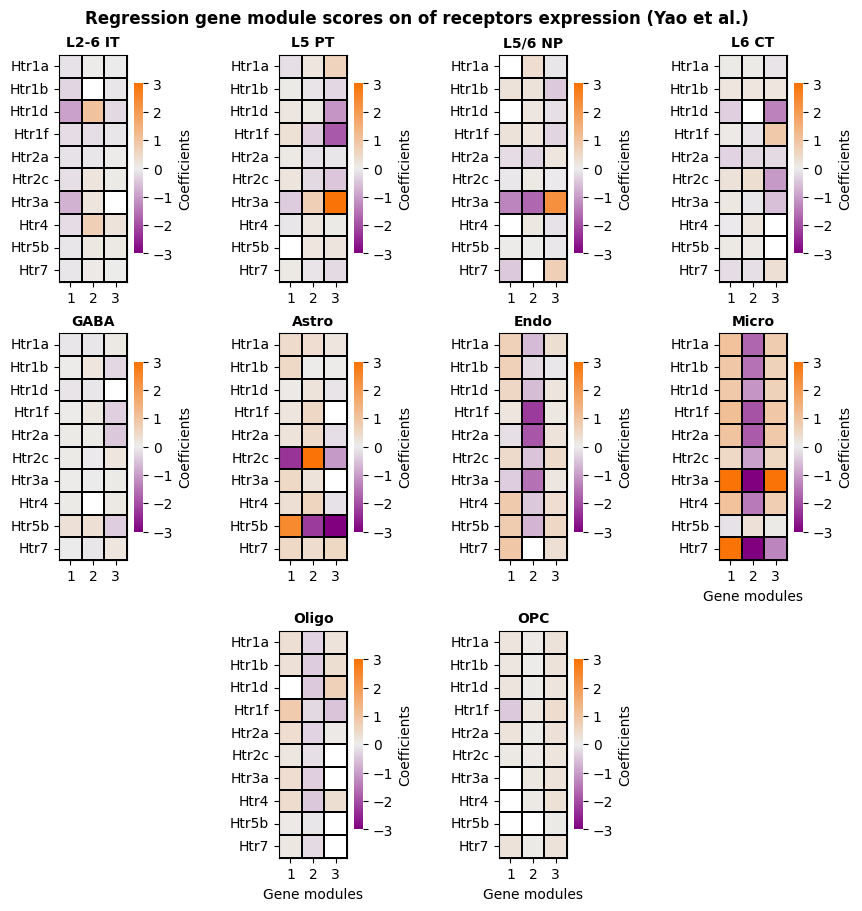

In [26]:
import statsmodels.api as sm

# Define a custom diverging color palette (purple → neutral beige → orange)
custom_colors = [
    "#800080",  # Purple (negative coefficients)
    "#ECECEC",  # Neutral beige (zero-centered)
    "#F97306",  # Orange (positive coefficients)
]

# Create the continuous color map
custom_map = mcolors.LinearSegmentedColormap.from_list("purple_orange", custom_colors, N=256)

# Prepare receptor and component column names
receptor_list = [gene.capitalize() for gene in sero_mouse]
cols = receptor_list.copy()
comp_cols = ['Component ' + str(col) for col in range(1, 4)]

# Define grid layout for visualization
n_cell_types = len(cell_types)
n_cols = 4
n_rows = 3

fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.2 * n_cols, 3 * n_rows), constrained_layout=True, dpi=100)
axes = axes.flatten()

# Add component names to the columns list for later merging
for comp in comp_cols:
    cols.append(comp)

# Store all coefficients in p-values in a dictionary
all_coefs = {}

# Loop through each cell type and its corresponding subclass
for i, (cell_type, cell_class) in enumerate(cell_mapping.items()):

    # Adjust index for empty subplots (to maintain visual layout)
    if i == 8:
        i = 9
    elif i == 9:
        i = 10

    # Get receptor and PLS component data for the given cell class
    sero_values = recep_dict[cell_class]
    comp_values = class_dict[cell_class][cell_type]
    comp_values['cell_label'] = comp_values.cell_label.astype(int)

    # Merge receptor expression with PLS component scores
    test_df = sero_values.merge(comp_values, on='cell_label')[cols].copy()

    # Initialize DataFrames to store regression coefficients and p-values
    coefs_df = pd.DataFrame()
    pvals_df = pd.DataFrame()

    # Loop through each PLS component to fit OLS models per receptor gene
    for arg, comp in enumerate(comp_cols):

        comp_coefs = []
        comp_pvals = []

        # Component scores as dependent variable
        y_comps = test_df[comp].values

        # Regress component scores on each receptor gene
        for gene in receptor_list:
            X = sm.add_constant(test_df[gene].values.reshape(-1, 1))  # gene as predictor
            ols_model = sm.OLS(y_comps, X).fit()
            comp_coefs.append(ols_model.params[1])
            comp_pvals.append(ols_model.pvalues[1])

        # Store regression results
        coefs_df[comp] = comp_coefs
        pvals_df[comp] = comp_pvals

    print('\n')

    # Format cell type labels for display
    if cell_type == 'L2-5_IT':
        cell_type = 'L2-6 IT'
    else:
        cell_type = cell_type.replace('-', '/').replace('_', ' ')

    # Plot heatmap of regression coefficients (masking non-significant results)
    heatmap = sns.heatmap(
        coefs_df.mask(pvals_df > 0.05),
        cmap=custom_map,
        vmax=3, vmin=-3,
        xticklabels=range(1, 4),
        yticklabels=receptor_list,
        square=True,
        ax=axes[i],
        cbar_kws={"shrink": 0.75, "label": "Coefficients"},
        linewidth=.1, linecolor='black'
    )

    axes[i].set_title(cell_type, fontweight='bold', fontsize=10)
    axes[i].spines[:].set_visible(True)
    axes[i].set_yticklabels(axes[i].get_yticklabels(), rotation=0, fontsize=10)

    coefs_df.index = receptor_list
    pvals_df.index= receptor_list

    all_coefs[cell_type] = coefs_df.round(3).to_dict(), pvals_df.round(3).to_dict()

with open("October_2025/regression_results/Yao_sero_coefs_pvals.json", "w") as f:
    json.dump(all_coefs, f, indent=4)

# Remove unused subplot axes for visual balance
fig.delaxes(axes[8])
fig.delaxes(axes[11])

# Label bottom row subplots
axes[i].set_xlabel('Gene modules')
axes[i-1].set_xlabel('Gene modules')
axes[i-2].set_xlabel('Gene modules')
axes[i-3].set_xlabel('Gene modules')

# Add figure title and save output
fig.suptitle('Regression gene module scores on of receptors expression (Yao et al.)', fontweight="bold", fontsize=12)
#plt.savefig('../../Figures/psilocybin_mouse_pls/Yao_regression_only_sero.svg', bbox_inches='tight', dpi=200)
plt.show()
plt.close('all')


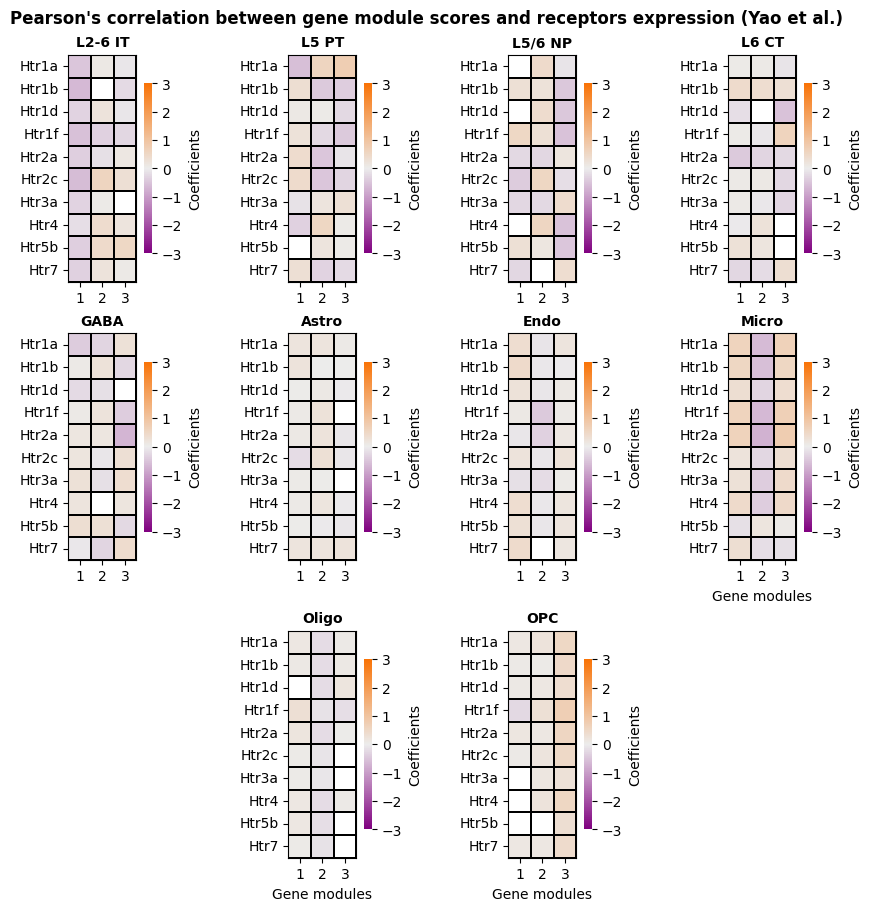

In [28]:
import statsmodels.api as sm

# Define a custom diverging color palette (purple → neutral beige → orange)
custom_colors = [
    "#800080",  # Purple (negative coefficients)
    "#ECECEC",  # Neutral beige (zero-centered)
    "#F97306",  # Orange (positive coefficients)
]

# Create the continuous color map
custom_map = mcolors.LinearSegmentedColormap.from_list("purple_orange", custom_colors, N=256)

# Prepare receptor and component column names
receptor_list = [gene.capitalize() for gene in sero_mouse]
cols = receptor_list.copy()
comp_cols = ['Component ' + str(col) for col in range(1, 4)]

# Define grid layout for visualization
n_cell_types = len(cell_types)
n_cols = 4
n_rows = 3

fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.2 * n_cols, 3 * n_rows), constrained_layout=True, dpi=100)
axes = axes.flatten()

# Add component names to the columns list for later merging
for comp in comp_cols:
    cols.append(comp)

# Store all coefficients in p-values in a dictionary
all_coefs = {}

# Loop through each cell type and its corresponding subclass
for i, (cell_type, cell_class) in enumerate(cell_mapping.items()):

    # Adjust index for empty subplots (to maintain visual layout)
    if i == 8:
        i = 9
    elif i == 9:
        i = 10

    # Get receptor and PLS component data for the given cell class
    sero_values = recep_dict[cell_class]
    comp_values = class_dict[cell_class][cell_type]
    comp_values['cell_label'] = comp_values.cell_label.astype(int)

    # Merge receptor expression with PLS component scores
    test_df = sero_values.merge(comp_values, on='cell_label')[cols].copy()

    # Initialize DataFrames to store regression coefficients and p-values
    coefs_df = pd.DataFrame()
    pvals_df = pd.DataFrame()

    # Loop through each PLS component to fit OLS models per receptor gene
    for arg, comp in enumerate(comp_cols):

        comp_coefs = []
        comp_pvals = []

        # Component scores as dependent variable
        y_comps = test_df[comp].values

        # Regress component scores on each receptor gene
        for gene in receptor_list:
            X = test_df[gene].values
            c, p  = scipy.stats.pearsonr(y_comps, X)
            comp_coefs.append(c)
            comp_pvals.append(p)

        # Store regression results
        coefs_df[comp] = comp_coefs
        pvals_df[comp] = comp_pvals

    print('\n')

    # Format cell type labels for display
    if cell_type == 'L2-5_IT':
        cell_type = 'L2-6 IT'
    else:
        cell_type = cell_type.replace('-', '/').replace('_', ' ')

    # Plot heatmap of regression coefficients (masking non-significant results)
    heatmap = sns.heatmap(
        coefs_df.mask(pvals_df > 0.05),
        cmap=custom_map,
        vmax=3, vmin=-3,
        xticklabels=range(1, 4),
        yticklabels=receptor_list,
        square=True,
        ax=axes[i],
        cbar_kws={"shrink": 0.75, "label": "Coefficients"},
        linewidth=.1, linecolor='black'
    )

    axes[i].set_title(cell_type, fontweight='bold', fontsize=10)
    axes[i].spines[:].set_visible(True)
    axes[i].set_yticklabels(axes[i].get_yticklabels(), rotation=0, fontsize=10)

    coefs_df.index = receptor_list
    pvals_df.index= receptor_list

    all_coefs[cell_type] = coefs_df.round(3).to_dict(), pvals_df.round(3).to_dict()

with open("October_2025/regression_results/Yao_sero_coefs_pvals.json", "w") as f:
    json.dump(all_coefs, f, indent=4)

# Remove unused subplot axes for visual balance
fig.delaxes(axes[8])
fig.delaxes(axes[11])

# Label bottom row subplots
axes[i].set_xlabel('Gene modules')
axes[i-1].set_xlabel('Gene modules')
axes[i-2].set_xlabel('Gene modules')
axes[i-3].set_xlabel('Gene modules')

# Add figure title and save output
fig.suptitle("Pearson's correlation between gene module scores and receptors expression (Yao et al.)", fontweight="bold", fontsize=12)
#plt.savefig('../../Figures/psilocybin_mouse_pls/Yao_regression_only_sero.svg', bbox_inches='tight', dpi=200)
plt.show()
plt.close('all')


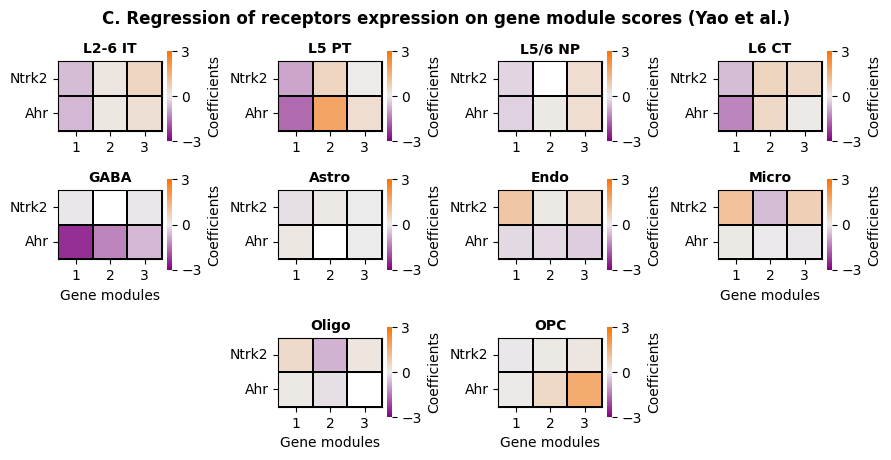

In [22]:
# Define the genes of interest and initialize variable names
cols = [gene.capitalize() for gene in ['Ntrk2', 'Ahr']]  # Standardize capitalization for gene names
comp_cols = ['Component ' + str(col) for col in range(1, 4)]  # Define component column names (1–3)

# Set up grid dimensions for plotting
n_cell_types = len(cell_types)  # Number of cell types to plot
n_cols = 4  # Number of columns in the subplot grid
n_rows = 3  # Number of rows in the subplot grid

# Create figure and axes grid for multiple cell-type plots
fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(2.2 * n_cols, 1.5 * n_rows),  # Adjust figure size proportionally to layout
    constrained_layout=True,
    dpi=100
)
axes = axes.flatten()  # Flatten axes array for easier iteration

# Append the component columns to the list of columns to keep
for comp in comp_cols:
    cols.append(comp)

# Iterate through cell types and their corresponding classes
for i, (cell_type, cell_class) in enumerate(cell_mapping.items()):

    # Adjust subplot indices to skip specific positions for layout reasons
    if i == 8:
        i = 9
    elif i == 9:
        i = 10

    # Retrieve receptor expression values and component scores for the current cell class
    sero_values = recep_dict[cell_class]
    comp_values = class_dict[cell_class][cell_type]
    comp_values['cell_label'] = comp_values.cell_label.astype(int)  # Ensure integer labels for merging

    # Merge receptor and component data on cell label and select relevant columns
    test_df = sero_values.merge(comp_values, on='cell_label')[cols].copy()

    # Initialize DataFrames to store regression coefficients and p-values
    coefs_df = pd.DataFrame()
    pvals_df = pd.DataFrame()

    # Loop through each gene module (component)
    for arg, comp in enumerate(comp_cols):
        comp_coefs = []  # Store regression coefficients for each gene
        comp_pvals = []  # Store corresponding p-values

        x_comps = test_df[comp]  # Extract the component (predictor)
        X = sm.add_constant(x_comps.values.reshape(-1, 1))  # Add intercept for regression

        # Perform OLS regression for each receptor gene
        for gene in ['Ntrk2', 'Ahr']:
            x = test_df[gene].values  # Gene expression (dependent variable)
            ols_model = sm.OLS(x, X).fit()  # Fit linear model
            comp_coefs.append(ols_model.params[1])  # Store beta coefficient for the component
            comp_pvals.append(ols_model.pvalues[1])  # Store p-value for the component term
            
        # Store results for this component
        coefs_df[comp] = comp_coefs
        pvals_df[comp] = comp_pvals

    print('\n')  # Add line spacing between cell types in console output

    # Adjust cell type labels for figure titles
    if cell_type == 'L2-5_IT':
        cell_type = 'L2-6 IT'
    else:
        cell_type = cell_type.replace('-', '/').replace('_', ' ')

    # Create a heatmap of regression coefficients, masking non-significant results (p > 0.05)
    heatmap = sns.heatmap(
        coefs_df.mask(pvals_df > 0.05),  
        cmap=custom_map,  
        vmax=3, vmin=-3, 
        xticklabels=range(1, 4),  
        yticklabels=cols[0:2], 
        square=True,
        ax=axes[i],
        cbar_kws={"shrink": 0.75, "label": "Coefficients"},
        linewidth=.1, linecolor='black' 
    )

    # Customize subplot aesthetics
    axes[i].set_title(cell_type, fontweight='bold', fontsize=10)
    axes[i].spines[:].set_visible(True)
    axes[i].set_yticklabels(axes[i].get_yticklabels(), rotation=0, fontsize=10)

    # Adjust colorbar tick positions for clarity
    cbar = heatmap.collections[0].colorbar
    cbar.set_ticks([-3, 0, 3])

    coefs_df.index = cols[0:2]
    pvals_df.index= cols[0:2]

    all_coefs[cell_type] = coefs_df.round(3).to_dict(), pvals_df.round(3).to_dict()

with open("October_2025/regression_results/Yao_non_sero_coefs_pvals.json", "w") as f:
    json.dump(all_coefs, f, indent=4)

# Remove unused subplots to clean up the figure layout
fig.delaxes(axes[8])
fig.delaxes(axes[11])

# Label x-axes for bottom-row subplots
axes[i].set_xlabel('Gene modules')
axes[i-1].set_xlabel('Gene modules')
axes[i-3].set_xlabel('Gene modules')
axes[i-6].set_xlabel('Gene modules')

# Add overall figure title
fig.suptitle(
    'C. Regression of receptors expression on gene module scores (Yao et al.)',
    fontweight="bold", fontsize=12
)

# Save and display the figure
plt.savefig('../../Figures/psilocybin_mouse_pls/Yeo_regression_non_sero.svg', bbox_inches='tight', dpi=200)
plt.show()
plt.close('all')


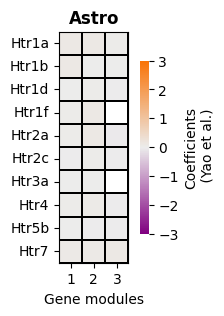

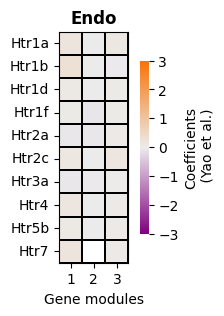

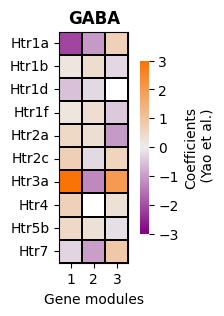

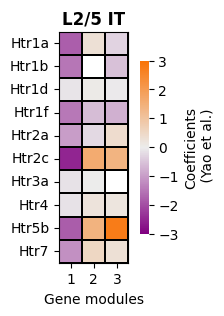

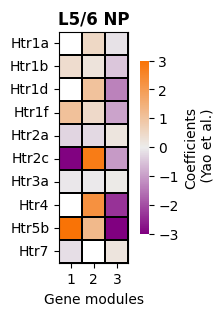

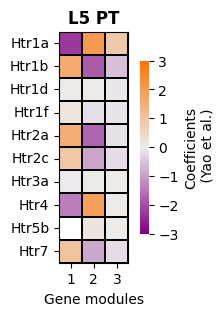

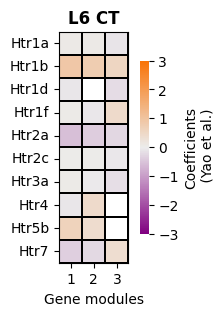

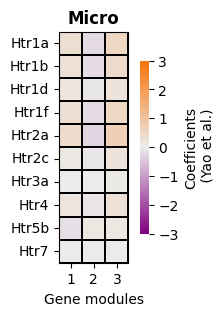

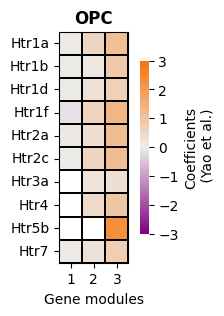

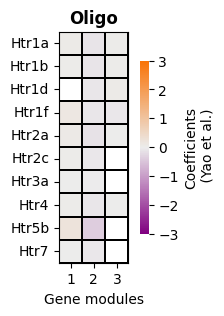

In [23]:
# Prepare columns and components for regression
cols = receptor_list.copy()
comp_cols = ['Component ' + str(col) for col in range(1, 4)]
for comp in comp_cols:
    cols.append(comp)

# Loop through sorted cell types and merge receptor expression with component scores
for i, (cell_type, cell_class) in enumerate(sorted_mapping.items()):

    sero_values = recep_dict[cell_class]
    comp_values = class_dict[cell_class][cell_type]
    comp_values['cell_label'] = comp_values.cell_label.astype(int)

    test_df = sero_values.merge(comp_values, on='cell_label')[cols].copy()

    coefs_df = pd.DataFrame()
    pvals_df = pd.DataFrame()

    # Regress each receptor gene on each component
    for arg, comp in enumerate(comp_cols):
        comp_coefs, comp_pvals = [], []
        X = sm.add_constant(test_df[comp].values.reshape(-1, 1))

        for gene in sero_mouse:
            ols_model = sm.OLS(test_df[gene].values, X).fit()
            comp_coefs.append(ols_model.params[1])
            comp_pvals.append(ols_model.pvalues[1])
            
        coefs_df[comp] = comp_coefs
        pvals_df[comp] = comp_pvals

    # Plot heatmap of regression coefficients, masking non-significant values
    plt.figure(figsize=(3,3), dpi=100)
    plt.title(cell_type.replace('-', '/').replace('_', ' '), fontweight='bold')
    fig = sns.heatmap(
        coefs_df.mask(pvals_df>0.05), cmap=custom_map, square=True,
        vmax=3, vmin=-3, yticklabels=sero_mouse, xticklabels=range(1,4),
        cbar_kws={"shrink": 0.75, "label":"Coefficients\n (Yao et al.)"},
        linewidth=.01, linecolor='black'
    )
    fig.spines[:].set_visible(True)
    plt.xlabel('Gene modules')
    plt.savefig(f'../../Figures/psilocybin_mouse_pls/MERFISH_flipped_{cell_type.replace("/", "_")}_{cell_type}.svg', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close('all')
